# PRCP-1020: House Price Prediction

## Project Overview

This project analyzes residential housing data from Ames, Iowa, to understand the factors associated with house sale prices and develop machine-learning models for price prediction.

## Objectives

1. Perform exploratory data analysis and prepare a complete data-analysis report.
2. Develop and evaluate machine-learning models to predict house sale prices.
3. Analyze relationships between property features and sale prices.
4. Compare model performance and recommend a suitable model for production.
5. Develop buyer-oriented recommendations based on price, location, and property characteristics.
6. Document data challenges, preprocessing techniques, and the reasoning behind the chosen approaches.

## Dataset

The dataset contains 1,460 property records and 81 columns, including the target variable `SalePrice`. The target represents the property's sale price in dollars.

## Methodology

The project will follow a structured workflow:

1. Load and validate the dataset.
2. Perform exploratory data analysis.
3. Prepare features and handle missing values.
4. Build preprocessing and modeling pipelines.
5. Compare models using consistent validation metrics.
6. Interpret feature relationships and model errors.
7. Develop buyer recommendations.
8. Document challenges, conclusions, and the final model recommendation.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Resolve the project root whether Jupyter starts in the project
# directory or in the notebooks directory.
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = (
    CURRENT_DIR.parent
    if CURRENT_DIR.name == "notebooks"
    else CURRENT_DIR
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "extracted"
    / "Data"
    / "data.csv"
)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}\n"
        "Check the project root and dataset location."
    )

df = pd.read_csv(DATA_PATH)

print("Project root:", PROJECT_ROOT.resolve())
print("Dataset path:", DATA_PATH.resolve())
print("Dataset shape:", df.shape)
print("SalePrice missing values:", df["SalePrice"].isna().sum())

display(df.head())

Project root: C:\Vishal\house-price-prediction
Dataset path: C:\Vishal\house-price-prediction\data\raw\extracted\Data\data.csv
Dataset shape: (1460, 81)
SalePrice missing values: 0


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.00,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.00",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.00,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.00",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.00,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.00",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.00,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.00",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.00,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.00",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1. Dataset Overview and Data Quality

This section examines the dataset's dimensions, data types, duplicate records, target integrity, and missing values. These checks help establish the reliability of the data before preprocessing and model development.

In [2]:
# Basic dataset quality checks
print("Dataset dimensions:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["Id"].duplicated().sum())
print("Missing target values:", df["SalePrice"].isna().sum())
print("Non-positive target values:", (df["SalePrice"] <= 0).sum())

print("\nData types:")
display(df.dtypes.value_counts().rename("column_count").to_frame())

print("\nTarget summary:")
display(df["SalePrice"].describe().to_frame().round(2))

print("\nMissing values by column:")
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
})

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_percent", ascending=False)
)

display(missing_summary.round(2))

Dataset dimensions: (1460, 81)
Duplicate rows: 0
Duplicate IDs: 0
Missing target values: 0
Non-positive target values: 0

Data types:


,column_count
str,43
int64,35
float64,3



Target summary:


,SalePrice
count,"1,460.00"
mean,"180,921.20"
std,"79,442.50"
min,"34,900.00"
25%,"129,975.00"
50%,"163,000.00"
75%,"214,000.00"
max,"755,000.00"



Missing values by column:


,missing_count,missing_percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


### Data Quality Findings

The dataset contains 1,460 observations and 81 columns, including the identifier `Id` and target `SalePrice`.

- No duplicate rows or duplicate identifiers were detected.
- `SalePrice` has no missing or non-positive values.
- The mean sale price is `$180,921.20`, while the median is `$163,000`. The mean exceeding the median suggests a right-skewed target distribution.
- The dataset contains 43 categorical (`str`), 35 integer, and 3 floating-point columns.
- Nineteen columns contain missing values. Missingness is particularly high in `PoolQC` (99.52%), `MiscFeature` (96.30%), `Alley` (93.77%), and `Fence` (80.75%).
- Other columns, including `LotFrontage`, `GarageYrBlt`, and `MasVnrArea`, have more moderate or limited missingness.

**Conclusion:** The target and identifiers pass the initial integrity checks. Missing values are the main data-quality issue and require feature-aware preprocessing. High missingness alone is not sufficient reason to delete a column because missingness may indicate that a property lacks the corresponding feature.### Data Quality Findings

The dataset contains 1,460 observations and 81 columns, including the identifier `Id` and target `SalePrice`.

- No duplicate rows or duplicate identifiers were detected.
- `SalePrice` has no missing or non-positive values.
- The mean sale price is `$180,921.20`, while the median is `$163,000`. The mean exceeding the median suggests a right-skewed target distribution.
- The dataset contains 43 categorical (`str`), 35 integer, and 3 floating-point columns.
- Nineteen columns contain missing values. Missingness is particularly high in `PoolQC` (99.52%), `MiscFeature` (96.30%), `Alley` (93.77%), and `Fence` (80.75%).
- Other columns, including `LotFrontage`, `GarageYrBlt`, and `MasVnrArea`, have more moderate or limited missingness.

**Conclusion:** The target and identifiers pass the initial integrity checks. Missing values are the main data-quality issue and require feature-aware preprocessing. High missingness alone is not sufficient reason to delete a column because missingness may indicate that a property lacks the corresponding feature.

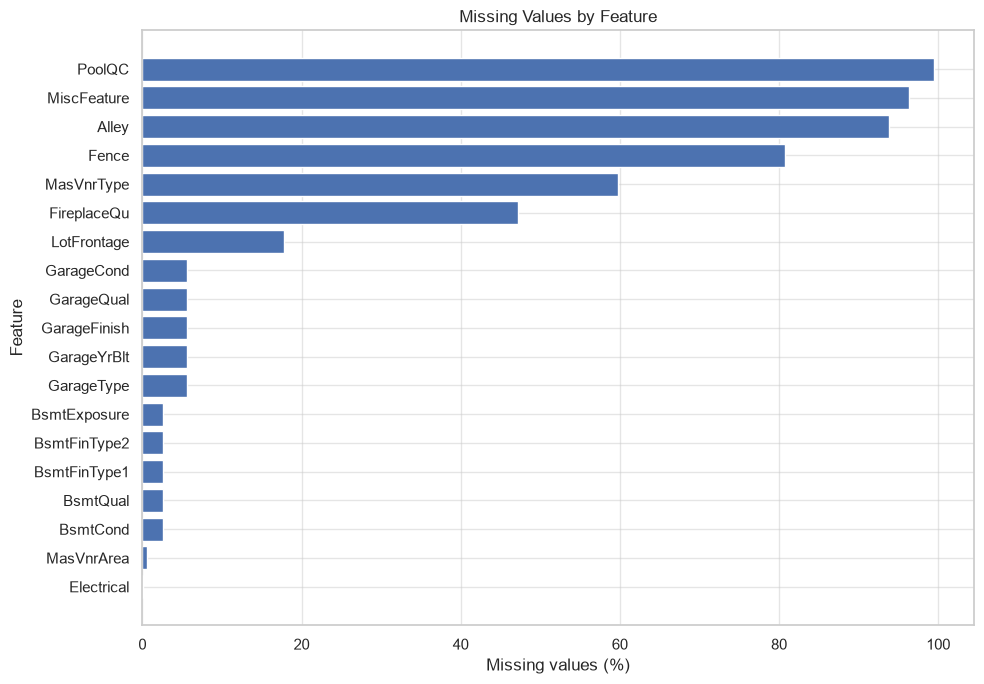

In [3]:
plt.figure(figsize=(10, 7))

missing_plot_data = missing_summary.sort_values(
    "missing_percent",
    ascending=True,
)

plt.barh(
    missing_plot_data.index,
    missing_plot_data["missing_percent"],
)

plt.title("Missing Values by Feature")
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Missing-Value Analysis

Missing values vary substantially across features. `PoolQC`, `MiscFeature`, `Alley`, and `Fence` have the highest missing percentages, while `Electrical` and `MasVnrArea` have very few missing values.

Some missing values may indicate that a property does not have a particular feature, such as a pool, garage, basement, or fireplace. Others may represent unknown measurements.

The distinction matters because indiscriminately replacing every missing value with a mean, median, or most-frequent category could introduce misleading information.

The preprocessing strategy will therefore distinguish structural missingness from unknown measurements wherever the dataset provides supporting evidence.

In [4]:
missingness_checks = {
    "PoolQC": ["PoolArea"],
    "GarageType": ["GarageCars", "GarageArea", "GarageYrBlt"],
    "BsmtQual": ["TotalBsmtSF", "BsmtFinSF1", "BsmtUnfSF"],
    "FireplaceQu": ["Fireplaces"],
}

for missing_feature, related_features in missingness_checks.items():
    missing_rows = df[df[missing_feature].isna()]

    print(f"\n{missing_feature}: {len(missing_rows)} missing rows")

    for related_feature in related_features:
        print(
            f"  {related_feature} == 0:",
            (missing_rows[related_feature] == 0).sum(),
            "of",
            len(missing_rows),
        )


PoolQC: 1453 missing rows
  PoolArea == 0: 1453 of 1453

GarageType: 81 missing rows
  GarageCars == 0: 81 of 81
  GarageArea == 0: 81 of 81
  GarageYrBlt == 0: 0 of 81

BsmtQual: 37 missing rows
  TotalBsmtSF == 0: 37 of 37
  BsmtFinSF1 == 0: 37 of 37
  BsmtUnfSF == 0: 37 of 37

FireplaceQu: 690 missing rows
  Fireplaces == 0: 690 of 690


### Structural Missingness Investigation

Four categorical features were investigated by comparing their missing values with related numerical features.

- **`PoolQC`:** All 1,453 missing rows have `PoolArea = 0`, suggesting the properties do not have pools.
- **`GarageType`:** All 81 missing rows have `GarageCars = 0` and `GarageArea = 0`, suggesting the properties do not have garages.
- **`BsmtQual`:** All 37 missing rows have `TotalBsmtSF = 0`, `BsmtFinSF1 = 0`, and `BsmtUnfSF = 0`, suggesting the properties do not have basements.
- **`FireplaceQu`:** All 690 missing rows have `Fireplaces = 0`, suggesting the properties do not have fireplaces.

**Preprocessing decision:** These patterns support representing the absence of the corresponding feature explicitly for the four investigated categorical columns. This avoids treating structural absence as an ordinary unknown value.

The evidence supports these interpretations for the observed rows. Other columns with missing values will be assessed separately rather than assigned the same rule automatically.

In [5]:
masvnr_missing = df["MasVnrType"].isna()

print("Rows with missing MasVnrType:", masvnr_missing.sum())
print(
    "Among these, MasVnrArea == 0:",
    (df.loc[masvnr_missing, "MasVnrArea"] == 0).sum(),
)
print(
    "Among these, MasVnrArea > 0:",
    (df.loc[masvnr_missing, "MasVnrArea"] > 0).sum(),
)
print(
    "Among these, MasVnrArea is also missing:",
    df.loc[masvnr_missing, "MasVnrArea"].isna().sum(),
)

display(
    df.loc[
        masvnr_missing
        & (df["MasVnrArea"].isna() | (df["MasVnrArea"] > 0)),
        [
            "Id",
            "MasVnrType",
            "MasVnrArea",
            "OverallQual",
            "Neighborhood",
            "SalePrice",
        ],
    ].sort_values("MasVnrArea", na_position="last")
)

Rows with missing MasVnrType: 872
Among these, MasVnrArea == 0: 859
Among these, MasVnrArea > 0: 5
Among these, MasVnrArea is also missing: 8


,Id,MasVnrType,MasVnrArea,OverallQual,Neighborhood,SalePrice
773,774,NaN,1.00,5,NAmes,114500
1230,1231,NaN,1.00,5,Sawyer,190000
624,625,NaN,288.00,6,NWAmes,165150
1334,1335,NaN,312.00,5,BrDale,125000
1300,1301,NaN,344.00,7,Gilbert,225000
234,235,NaN,NaN,6,Gilbert,216500
529,530,NaN,NaN,6,Crawfor,200624
650,651,NaN,NaN,7,Somerst,205950
936,937,NaN,NaN,7,SawyerW,184900
973,974,NaN,NaN,7,Somerst,182000


### Masonry Veneer Missing-Value Investigation

The `MasVnrType` feature has 872 missing values.

- In 859 rows, `MasVnrArea` is zero, suggesting that masonry veneer is absent.
- In five rows, `MasVnrArea` is positive despite the missing veneer type.
- In eight rows, both `MasVnrType` and `MasVnrArea` are missing.

**Preprocessing decision:** Missing veneer types associated with zero area can reasonably be represented as an absence category. However, missing types associated with positive areas should remain distinguishable from confirmed absence. Rows with both fields missing require a separate treatment because the dataset does not establish whether veneer is absent.

The original dataset will remain unchanged. These rules will be implemented in the preprocessing pipeline and evaluated as part of model development.

In [6]:
numerical_missing = (
    df.select_dtypes(include=["number"])
    .isna()
    .sum()
    .loc[lambda values: values > 0]
    .sort_values(ascending=False)
)

numerical_missing_summary = pd.DataFrame({
    "missing_count": numerical_missing,
    "missing_percent": (
        numerical_missing / len(df) * 100
    ),
})

display(numerical_missing_summary.round(2))

,missing_count,missing_percent
LotFrontage,259,17.74
GarageYrBlt,81,5.55
MasVnrArea,8,0.55


### Numerical Missing-Value Findings

Three numerical columns contain missing values:

- `LotFrontage`: 259 missing values (17.74%).
- `GarageYrBlt`: 81 missing values (5.55%).
- `MasVnrArea`: 8 missing values (0.55%).

**Initial preprocessing strategy:**

- Use median imputation as the baseline treatment for `LotFrontage`, with neighborhood-aware imputation considered as an experiment.
- Use median imputation for `GarageYrBlt` while retaining information about garage availability through related features.
- Handle `MasVnrArea` consistently with `MasVnrType`, since the two features jointly describe masonry veneer.

Imputation statistics will be fitted using the training data within the preprocessing pipeline. This prevents information from the validation set from influencing preprocessing decisions.

In [7]:
lotfrontage_summary = (
    df.groupby("Neighborhood", observed=True)["LotFrontage"]
    .agg(
        observed_count="count",
        missing_count=lambda values: values.isna().sum(),
        median_frontage="median",
    )
    .sort_values("median_frontage", ascending=False)
)

display(lotfrontage_summary.round(2))

print(
    "\nOverall LotFrontage median:",
    round(df["LotFrontage"].median(), 2),
)

,observed_count,missing_count,median_frontage
Neighborhood,,,
NoRidge,33,8,91.00
NridgHt,76,1,88.50
Timber,30,8,85.00
NWAmes,45,28,80.00
ClearCr,13,15,80.00
Crawfor,41,10,74.00
Somerst,78,8,73.50
NAmes,186,39,73.00
Mitchel,36,13,73.00



Overall LotFrontage median: 69.0


### LotFrontage and Neighborhood

The median `LotFrontage` differs across neighborhoods, ranging from 21 feet in BrDale and MeadowV to 91 feet in NoRidge. The overall median is 69 feet.

Several neighborhoods also have substantial missingness, including Gilbert (30 missing values), NWAmes (28), and Sawyer (26).

**Preprocessing implication:** Neighborhood-aware median imputation is a reasonable candidate because frontage measurements vary by neighborhood. However, some neighborhoods have few observed values, so the strategy must account for small groups and unseen categories.

The baseline will use training-set median imputation. A neighborhood-aware alternative can be evaluated later using the same validation split and model metrics.

SalePrice summary statistics:


,SalePrice
count,"1,460.00"
mean,"180,921.20"
std,"79,442.50"
min,"34,900.00"
25%,"129,975.00"
50%,"163,000.00"
75%,"214,000.00"
max,"755,000.00"



SalePrice skewness: 1.883
SalePrice kurtosis: 6.536


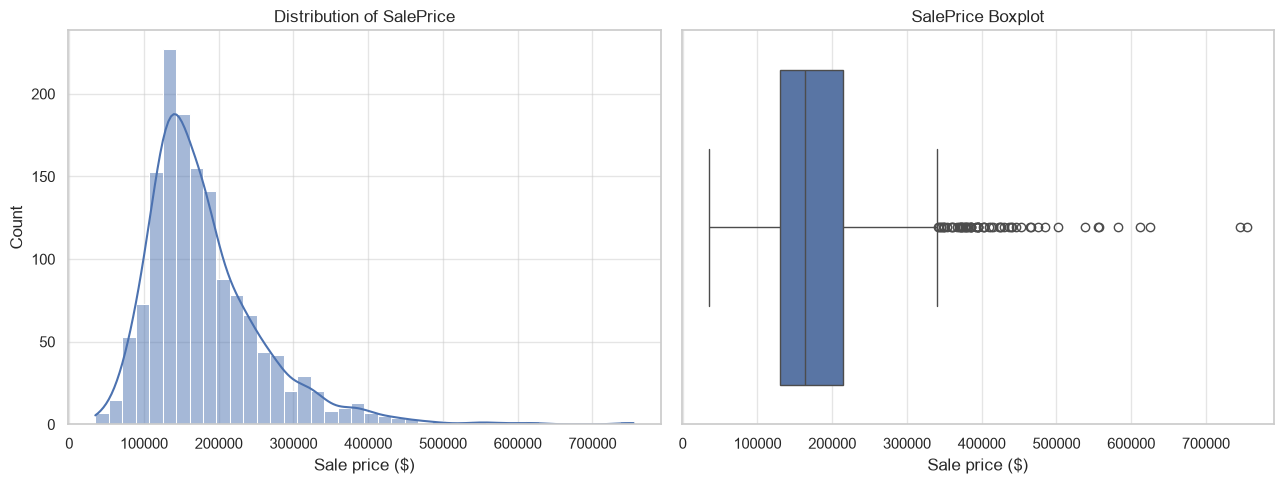

In [8]:
print("SalePrice summary statistics:")
display(df["SalePrice"].describe().to_frame().round(2))

print("\nSalePrice skewness:", round(df["SalePrice"].skew(), 3))
print("SalePrice kurtosis:", round(df["SalePrice"].kurtosis(), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    df["SalePrice"],
    bins=40,
    kde=True,
    ax=axes[0],
)
axes[0].set_title("Distribution of SalePrice")
axes[0].set_xlabel("Sale price ($)")

sns.boxplot(
    x=df["SalePrice"],
    ax=axes[1],
)
axes[1].set_title("SalePrice Boxplot")
axes[1].set_xlabel("Sale price ($)")

plt.tight_layout()
plt.show()

### Target Variable Analysis

The target variable `SalePrice` represents the property's sale price in dollars.

- The mean sale price is `$180,921.20`, while the median is `$163,000`.
- Sale prices range from `$34,900` to `$755,000`.
- The target has skewness of 1.883 and kurtosis of 6.536.
- The difference between the mean and median, together with positive skewness, indicates a right-skewed target distribution.

**Modeling implications:** A small number of expensive homes may have a substantial influence on model fitting and prediction errors. Models will be evaluated using a consistent validation strategy. A log-transformed target may be tested as an alternative, with predictions converted back to dollars before calculating evaluation metrics.

Original SalePrice skewness: 1.883
Log-transformed SalePrice skewness: 0.121


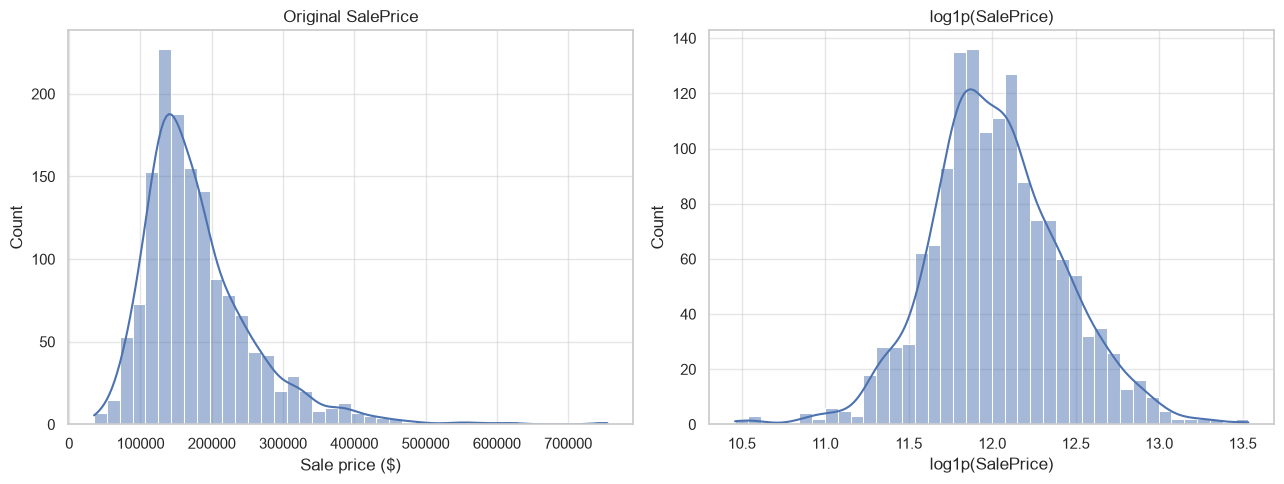

In [9]:
log_saleprice = np.log1p(df["SalePrice"])

print("Original SalePrice skewness:", round(df["SalePrice"].skew(), 3))
print("Log-transformed SalePrice skewness:", round(log_saleprice.skew(), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    df["SalePrice"],
    bins=40,
    kde=True,
    ax=axes[0],
)
axes[0].set_title("Original SalePrice")
axes[0].set_xlabel("Sale price ($)")

sns.histplot(
    log_saleprice,
    bins=40,
    kde=True,
    ax=axes[1],
)
axes[1].set_title("log1p(SalePrice)")
axes[1].set_xlabel("log1p(SalePrice)")

plt.tight_layout()
plt.show()

### Target Transformation Experiment

The `log1p` transformation was applied to `SalePrice` for exploratory comparison.

| Target representation | Skewness |
|---|---:|
| Original `SalePrice` | 1.883 |
| `log1p(SalePrice)` | 0.120 |

The transformed target is substantially less skewed than the original target.

**Conclusion:** Training a regression model on `log1p(SalePrice)` is a promising experiment. However, reduced skewness alone does not establish better predictive performance. The original-target and transformed-target approaches will be compared using consistent validation data and metrics calculated in dollars after converting predictions back to the original scale.

,Pearson correlation with SalePrice
OverallQual,0.79
GrLivArea,0.71
GarageCars,0.64
GarageArea,0.62
TotalBsmtSF,0.61
1stFlrSF,0.61
FullBath,0.56
TotRmsAbvGrd,0.53
YearBuilt,0.52
YearRemodAdd,0.51


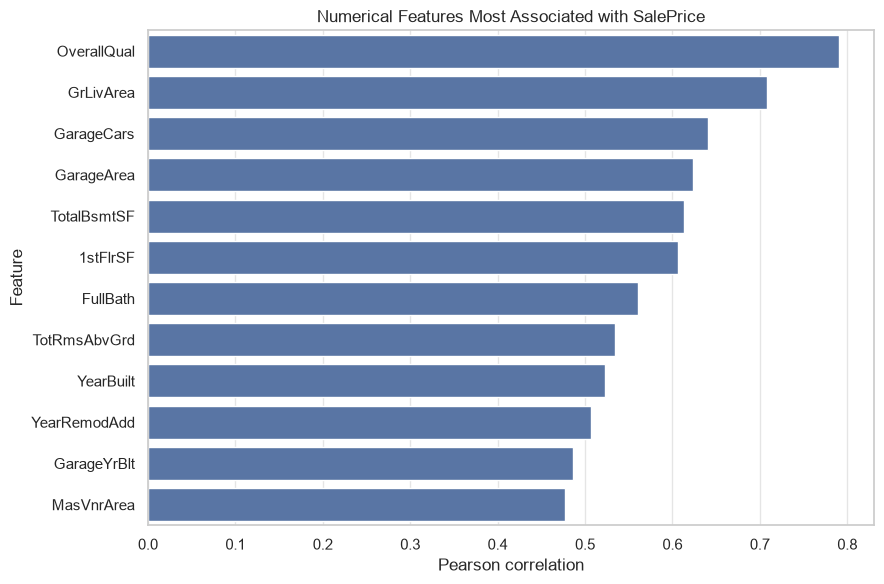

In [10]:
numeric_features = (
    df.select_dtypes(include=["number"])
    .columns
    .difference(["Id", "SalePrice"])
    .tolist()
)

correlations = (
    df[numeric_features]
    .corrwith(df["SalePrice"])
    .sort_values(key=abs, ascending=False)
)

top_correlations = correlations.head(12)

display(
    top_correlations
    .rename("Pearson correlation with SalePrice")
    .to_frame()
    .round(3)
)

plt.figure(figsize=(9, 6))

sns.barplot(
    x=top_correlations.values,
    y=top_correlations.index,
)

plt.title("Numerical Features Most Associated with SalePrice")
plt.xlabel("Pearson correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Feature Relationships with SalePrice

Pearson correlation analysis identified the following prominent numerical relationships:

- `OverallQual` has the strongest correlation with `SalePrice` (0.79).
- `GrLivArea` has a strong positive correlation (0.71).
- `GarageCars` (0.64), `GarageArea` (0.62), `TotalBsmtSF` (0.61), and `1stFlrSF` (0.61) are also strongly associated with sale price.
- `FullBath` (0.56), `TotRmsAbvGrd` (0.53), `YearBuilt` (0.52), and `YearRemodAdd` (0.51) have moderate positive correlations.

**Conclusion:** Overall quality and living area are promising predictors. Garage, basement, floor-area, and year-related variables may provide additional predictive information. These relationships will be examined alongside categorical features and evaluated through model validation. Correlation does not establish causation or measure a feature's independent contribution.

,property_count,median_price,mean_price
Neighborhood,,,
NridgHt,77,"315,000.00","316,270.62"
NoRidge,41,"301,500.00","335,295.32"
StoneBr,25,"278,000.00","310,499.00"
Timber,38,"228,475.00","242,247.45"
Somerst,86,"225,500.00","225,379.84"
Veenker,11,"218,000.00","238,772.73"
Crawfor,51,"200,624.00","210,624.73"
ClearCr,28,"200,250.00","212,565.43"
CollgCr,150,"197,200.00","197,965.77"


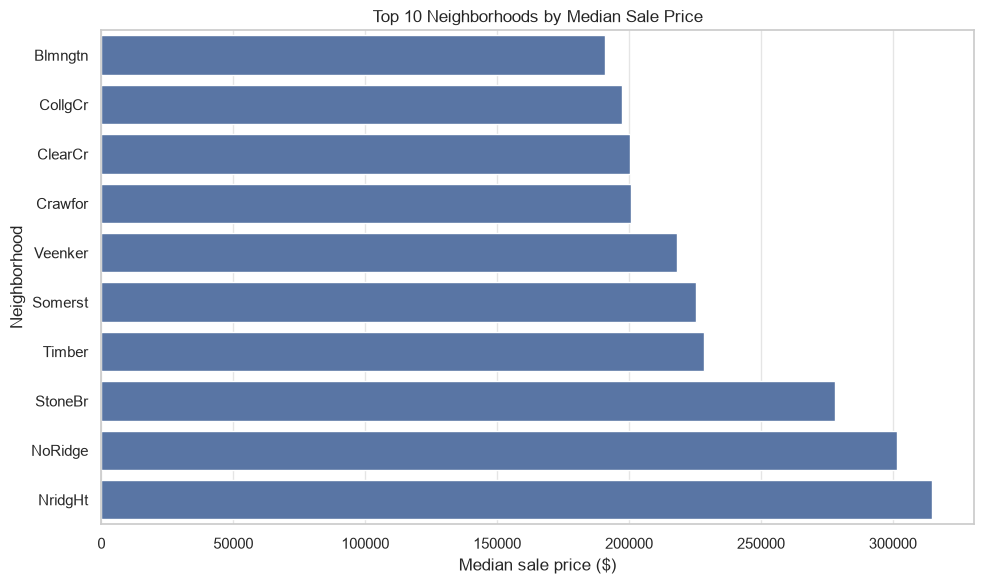

In [11]:
neighborhood_summary = (
    df.groupby("Neighborhood", observed=True)["SalePrice"]
    .agg(
        property_count="count",
        median_price="median",
        mean_price="mean",
    )
    .sort_values("median_price", ascending=False)
)

display(neighborhood_summary.round(2))

top_neighborhoods = neighborhood_summary.head(10).sort_values(
    "median_price",
    ascending=True,
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_neighborhoods.reset_index(),
    x="median_price",
    y="Neighborhood",
)

plt.title("Top 10 Neighborhoods by Median Sale Price")
plt.xlabel("Median sale price ($)")
plt.ylabel("Neighborhood")
plt.tight_layout()
plt.show()

### Neighborhood-Level Price Analysis

Median and mean sale prices were compared across the 25 neighborhoods.

- `NridgHt` has the highest median sale price at `$315,000`, based on 77 properties.
- `NoRidge` has the second-highest median at `$301,500`, based on 41 properties.
- `StoneBr` ranks third, with a median of `$278,000` across 25 properties.
- `NAmes` contains the largest number of observations (225) and has a median sale price of `$140,000`.
- `MeadowV` has the lowest median sale price at `$88,000`, based on 17 properties.
- `Blueste` has only two observations, so its median is less reliable than estimates based on larger samples.

The difference between the highest and lowest neighborhood medians is `$227,000`.

**Conclusion:** Neighborhood is a potentially important predictor and a useful dimension for buyer-oriented analysis. Neighborhood comparisons should be interpreted alongside property characteristics and sample sizes; they do not establish causal effects or guarantee the price of an individual property.

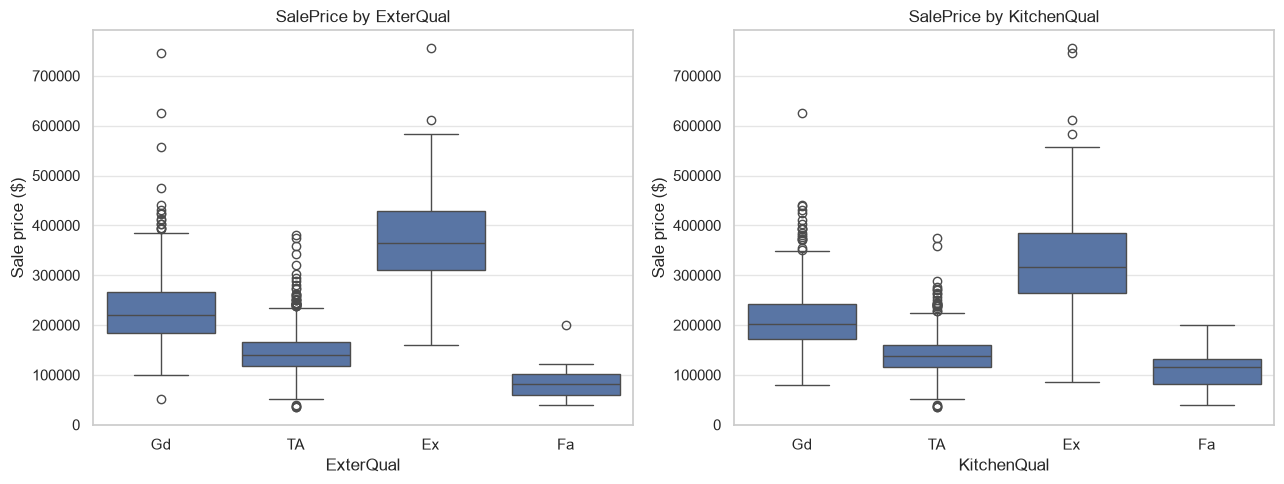


Median SalePrice by ExterQual:


,count,median
ExterQual,,
Ex,52,"364,606.50"
Gd,488,"220,000.00"
TA,906,"139,450.00"
Fa,14,"82,250.00"



Median SalePrice by KitchenQual:


,count,median
KitchenQual,,
Ex,100,"316,750.00"
Gd,586,"201,400.00"
TA,735,"137,000.00"
Fa,39,"115,000.00"


In [12]:
quality_features = ["ExterQual", "KitchenQual"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, feature in zip(axes, quality_features):
    sns.boxplot(
        data=df,
        x=feature,
        y="SalePrice",
        ax=ax,
    )
    ax.set_title(f"SalePrice by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Sale price ($)")

plt.tight_layout()
plt.show()

for feature in quality_features:
    print(f"\nMedian SalePrice by {feature}:")
    summary = (
        df.groupby(feature, observed=True)["SalePrice"]
        .agg(["count", "median"])
        .sort_values("median", ascending=False)
    )
    display(summary.round(2))

### Exterior and Kitchen Quality Analysis

Median sale prices were compared across exterior and kitchen quality categories.

**Exterior quality (`ExterQual`)**
- Excellent (`Ex`): `$364,606.50`, based on 52 properties.
- Good (`Gd`): `$220,000`, based on 488 properties.
- Typical/Average (`TA`): `$139,450`, based on 906 properties.
- Fair (`Fa`): `$82,250`, based on 14 properties.

**Kitchen quality (`KitchenQual`)**
- Excellent (`Ex`): `$316,750`, based on 100 properties.
- Good (`Gd`): `$201,400`, based on 586 properties.
- Typical/Average (`TA`): `$137,000`, based on 735 properties.
- Fair (`Fa`): `$115,000`, based on 39 properties.

Median sale price increases consistently across the observed quality categories for both features.

**Conclusion:** Exterior and kitchen quality are promising predictors and useful considerations for buyers comparing properties. These comparisons are descriptive and do not isolate the causal effect of quality upgrades. Smaller category counts also limit the reliability of some estimates.

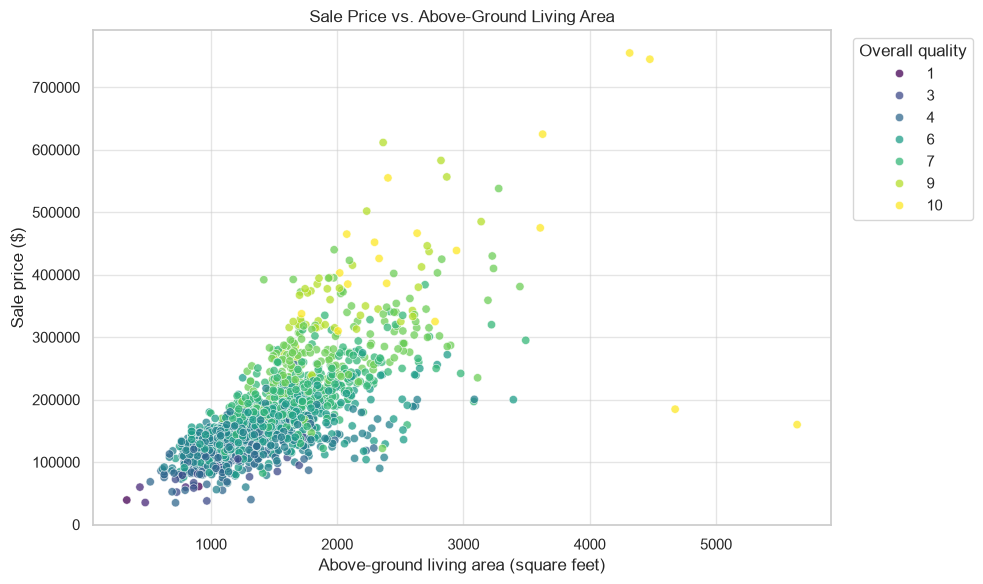

In [13]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    alpha=0.75,
)

plt.title("Sale Price vs. Above-Ground Living Area")
plt.xlabel("Above-ground living area (square feet)")
plt.ylabel("Sale price ($)")
plt.legend(title="Overall quality", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

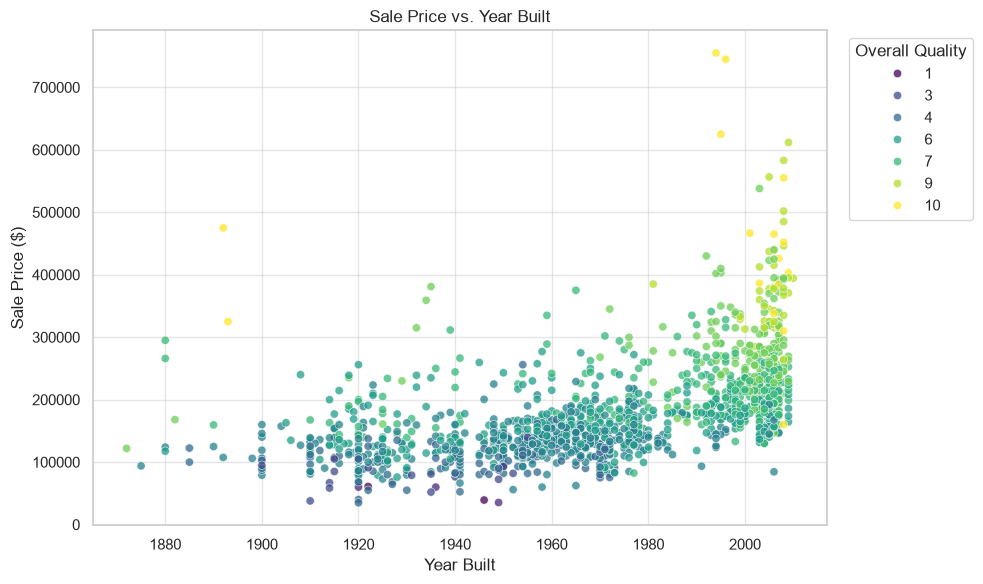

In [14]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="SalePrice",
    hue="OverallQual",
    palette="viridis",
    alpha=0.75
)

plt.title("Sale Price vs. Year Built")
plt.xlabel("Year Built")
plt.ylabel("Sale Price ($)")
plt.legend(
    title="Overall Quality",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

In [15]:
quality_price = (
    df.groupby("OverallQual")["SalePrice"]
    .agg(["count", "median", "mean"])
    .round(2)
    .reset_index()
)

quality_price.columns = [
    "Overall Quality",
    "Number of Houses",
    "Median Sale Price",
    "Mean Sale Price"
]

display(quality_price)

,Overall Quality,Number of Houses,Median Sale Price,Mean Sale Price
0,1,2,"50,150.00","50,150.00"
1,2,3,"60,000.00","51,770.33"
2,3,20,"86,250.00","87,473.75"
3,4,116,"108,000.00","108,420.66"
4,5,397,"133,000.00","133,523.35"
5,6,374,"160,000.00","161,603.03"
6,7,319,"200,141.00","207,716.42"
7,8,168,"269,750.00","274,735.54"
8,9,43,"345,000.00","367,513.02"
9,10,18,"432,390.00","438,588.39"


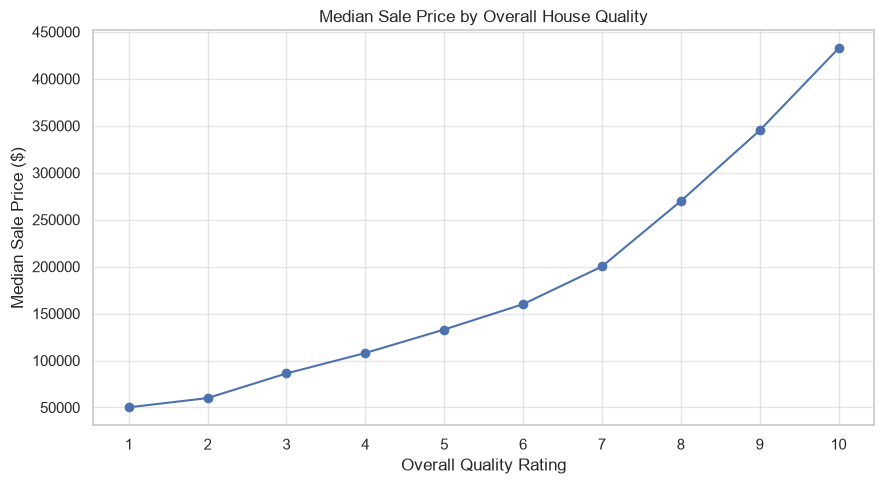

In [16]:
quality_median = df.groupby("OverallQual")["SalePrice"].median()

plt.figure(figsize=(9, 5))
plt.plot(
    quality_median.index,
    quality_median.values,
    marker="o"
)

plt.title("Median Sale Price by Overall House Quality")
plt.xlabel("Overall Quality Rating")
plt.ylabel("Median Sale Price ($)")
plt.xticks(quality_median.index)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

In [17]:
correlation = df["GrLivArea"].corr(df["SalePrice"])

print(f"Correlation between GrLivArea and SalePrice: {correlation:.3f}")

Correlation between GrLivArea and SalePrice: 0.709


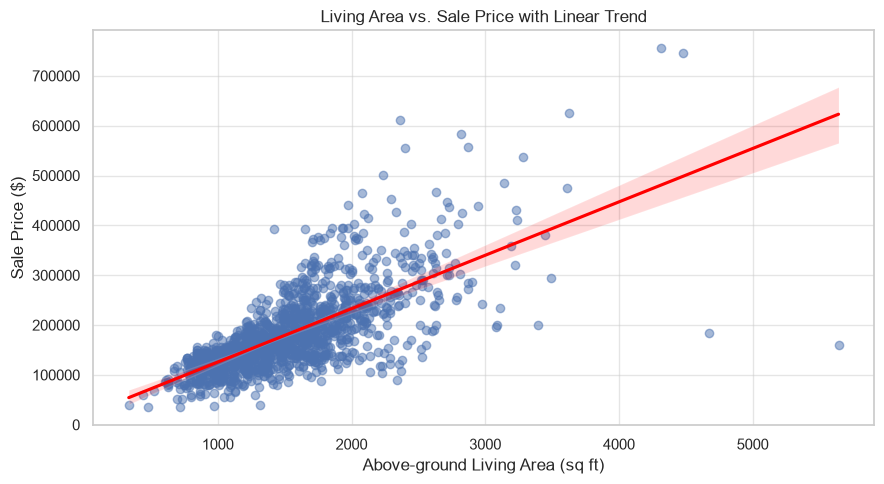

In [18]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x="GrLivArea",
    y="SalePrice",
    scatter_kws={"alpha": 0.5},
    line_kws={"color": "red"}
)

plt.title("Living Area vs. Sale Price with Linear Trend")
plt.xlabel("Above-ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

In [19]:
df.nlargest(10, "GrLivArea")[
    ["Id", "GrLivArea", "OverallQual", "YearBuilt", "Neighborhood", "SalePrice"]
].sort_values("GrLivArea", ascending=False)

,Id,GrLivArea,OverallQual,YearBuilt,Neighborhood,SalePrice
1298,1299,5642,10,2008,Edwards,160000
523,524,4676,10,2007,Edwards,184750
1182,1183,4476,10,1996,NoRidge,745000
691,692,4316,10,1994,NoRidge,755000
1169,1170,3627,10,1995,NoRidge,625000
185,186,3608,10,1892,OldTown,475000
304,305,3493,7,1880,OldTown,295000
1268,1269,3447,8,1935,Crawfor,381000
635,636,3395,6,1914,SWISU,200000
769,770,3279,8,2003,StoneBr,538000


In [20]:
ids_to_check = [1298, 523, 1182, 691]

columns_to_check = [
    "Id",
    "Neighborhood",
    "GrLivArea",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "GarageCars",
    "GarageArea",
    "SaleCondition",
    "SalePrice"
]

display(
    df.loc[df["Id"].isin(ids_to_check), columns_to_check]
    .sort_values("GrLivArea", ascending=False)
)


,Id,Neighborhood,GrLivArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,TotalBsmtSF,1stFlrSF,2ndFlrSF,GarageCars,GarageArea,SaleCondition,SalePrice
522,523,BrkSide,1664,6,7,1947,1950,1004,1004,660,2,420,Normal,159000
1181,1182,Crawfor,1652,8,5,2008,2008,1600,1652,0,2,482,Partial,392500
1297,1298,Edwards,1072,6,5,2005,2006,547,1072,0,2,525,Partial,140000
690,691,CollgCr,848,6,5,2004,2004,848,848,0,2,420,Normal,141000


In [21]:
ids_to_check = [1298, 523, 1182, 691]

columns_to_check = [
    "Id",
    "Neighborhood",
    "GrLivArea",
    "OverallQual",
    "OverallCond",
    "YearBuilt",
    "YearRemodAdd",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "GarageCars",
    "GarageArea",
    "SaleCondition",
    "SalePrice"
]

result = (
    df.loc[df["Id"].isin(ids_to_check), columns_to_check]
    .sort_values("GrLivArea", ascending=False)
)

print(result.to_string(index=False))

  Id Neighborhood  GrLivArea  OverallQual  OverallCond  YearBuilt  YearRemodAdd  TotalBsmtSF  1stFlrSF  2ndFlrSF  GarageCars  GarageArea SaleCondition  SalePrice
 523      BrkSide       1664            6            7       1947          1950         1004      1004       660           2         420        Normal     159000
1182      Crawfor       1652            8            5       2008          2008         1600      1652         0           2         482       Partial     392500
1298      Edwards       1072            6            5       2005          2006          547      1072         0           2         525       Partial     140000
 691      CollgCr        848            6            5       2004          2004          848       848         0           2         420        Normal     141000


In [22]:
largest_houses = (
    df.nlargest(10, "GrLivArea")[
        ["Id", "GrLivArea", "OverallQual", "YearBuilt", "Neighborhood", "SalePrice"]
    ]
    .sort_values("GrLivArea", ascending=False)
)

print(largest_houses.to_string(index=False))

  Id  GrLivArea  OverallQual  YearBuilt Neighborhood  SalePrice
1299       5642           10       2008      Edwards     160000
 524       4676           10       2007      Edwards     184750
1183       4476           10       1996      NoRidge     745000
 692       4316           10       1994      NoRidge     755000
1170       3627           10       1995      NoRidge     625000
 186       3608           10       1892      OldTown     475000
 305       3493            7       1880      OldTown     295000
1269       3447            8       1935      Crawfor     381000
 636       3395            6       1914        SWISU     200000
 770       3279            8       2003      StoneBr     538000


In [23]:
neighborhood_prices = (
    df.groupby("Neighborhood")["SalePrice"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
    .round(2)
)

neighborhood_prices.columns = [
    "Number of Houses",
    "Median Sale Price",
    "Mean Sale Price"
]

display(neighborhood_prices)

,Number of Houses,Median Sale Price,Mean Sale Price
Neighborhood,,,
NridgHt,77,"315,000.00","316,270.62"
NoRidge,41,"301,500.00","335,295.32"
StoneBr,25,"278,000.00","310,499.00"
Timber,38,"228,475.00","242,247.45"
Somerst,86,"225,500.00","225,379.84"
Veenker,11,"218,000.00","238,772.73"
Crawfor,51,"200,624.00","210,624.73"
ClearCr,28,"200,250.00","212,565.43"
CollgCr,150,"197,200.00","197,965.77"


### Neighborhood and Sale Price Analysis

The analysis reveals substantial differences in median sale prices across neighborhoods. NridgHt has the highest median sale price at `$315,000`, followed by NoRidge at `$301,500` and StoneBr at `$278,000`. MeadowV has the lowest median at `$88,000`.

These differences suggest that neighborhood is an important feature for house price prediction. Properties with similar physical characteristics may have different market values depending on their location. Neighborhood-level statistics should be interpreted cautiously when the number of observations is small. These findings indicate association, not causation.

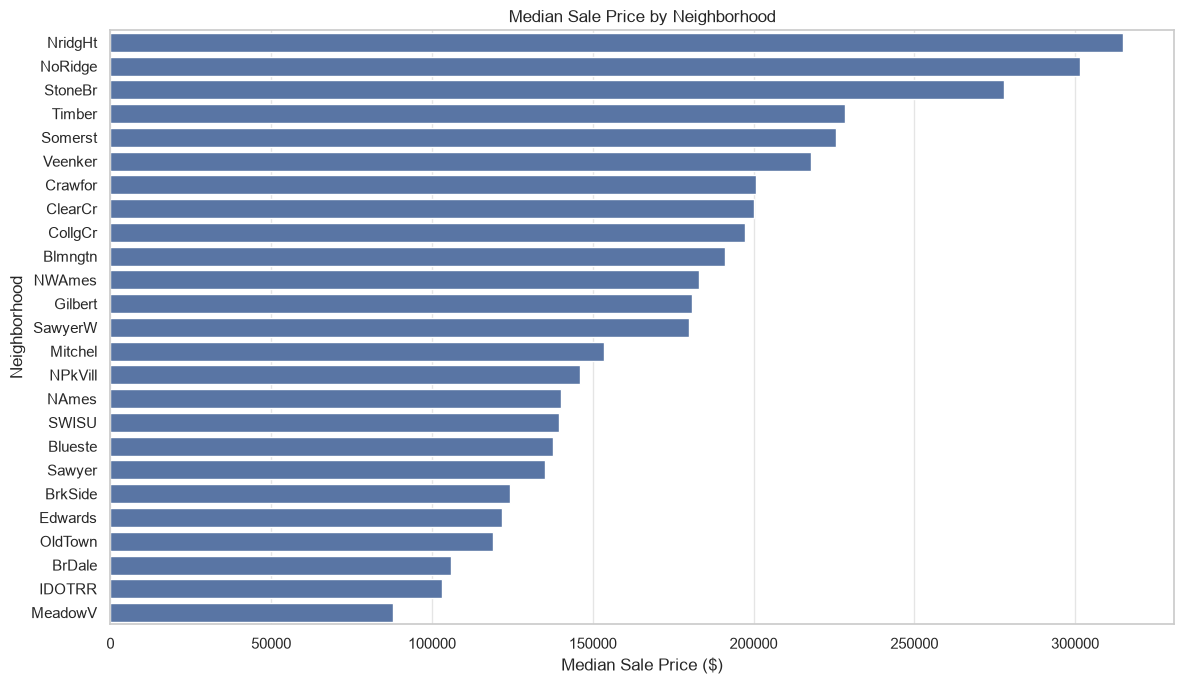

In [24]:
neighborhood_median = (
    df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=neighborhood_median.values,
    y=neighborhood_median.index
)

plt.title("Median Sale Price by Neighborhood")
plt.xlabel("Median Sale Price ($)")
plt.ylabel("Neighborhood")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

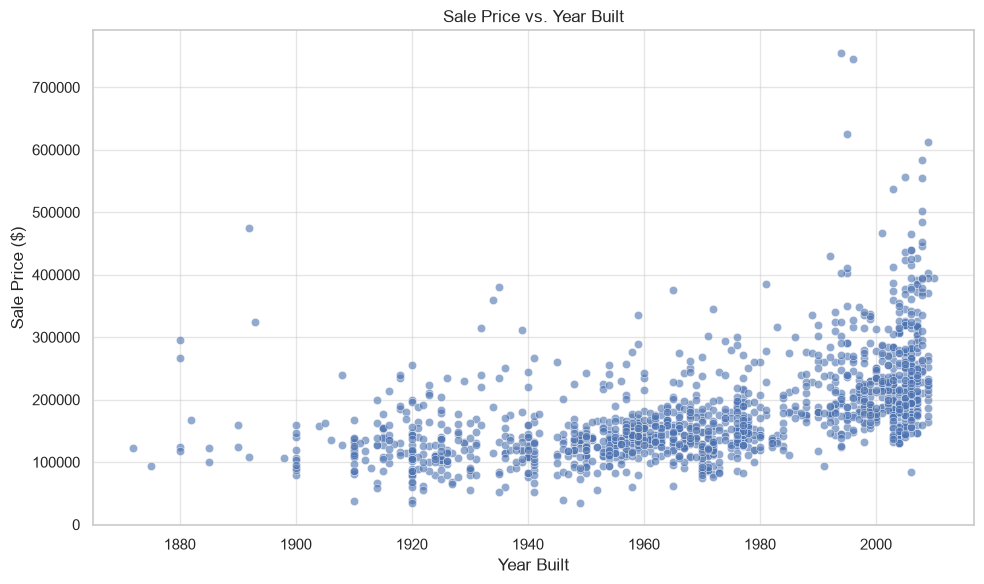

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="YearBuilt",
    y="SalePrice",
    alpha=0.6
)

plt.title("Sale Price vs. Year Built")
plt.xlabel("Year Built")
plt.ylabel("Sale Price ($)")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

In [26]:
correlation = df["YearBuilt"].corr(df["SalePrice"])

print(f"Correlation between YearBuilt and SalePrice: {correlation:.3f}")

Correlation between YearBuilt and SalePrice: 0.523


### Construction Year and Sale Price

The Pearson correlation between `YearBuilt` and `SalePrice` is 0.523, indicating a moderate positive linear relationship. In general, newer houses tend to have higher sale prices, although the relationship is not consistent for every property. Other factors, including overall quality, living area, neighborhood, and renovation history, may also contribute to differences in sale price.

In [27]:
correlation = df["YearRemodAdd"].corr(df["SalePrice"])

print(
    "Correlation between YearRemodAdd and SalePrice: "
    f"{correlation:.3f}"
)

Correlation between YearRemodAdd and SalePrice: 0.507


### Remodeling Year and Sale Price

The Pearson correlation between `YearRemodAdd` and `SalePrice` is 0.507, indicating a moderate positive linear relationship. Properties remodeled more recently tend to have higher sale prices, although the relationship is not consistent for every property. Remodeling year may provide useful information for prediction alongside construction year, overall quality, living area, and neighborhood.

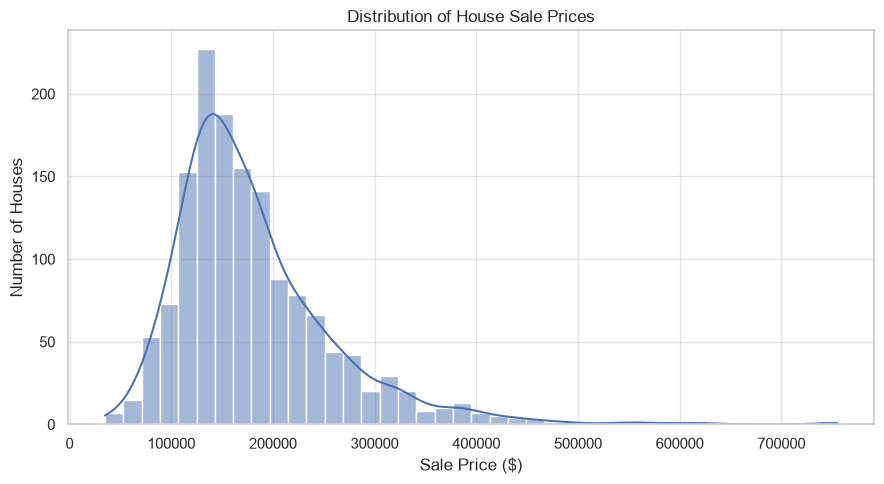

In [28]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="SalePrice", bins=40, kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of Houses")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

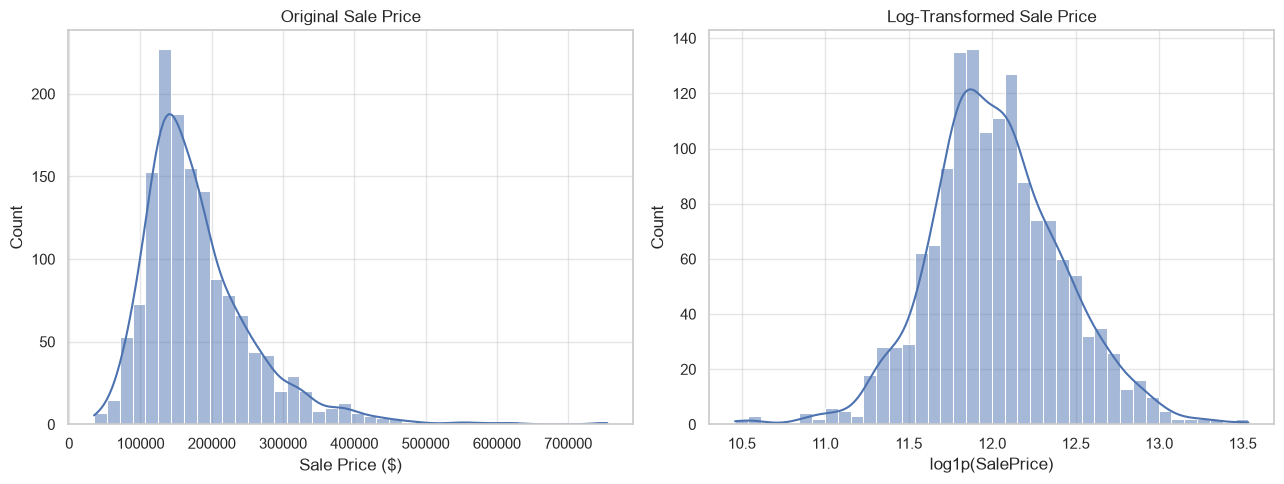

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(df["SalePrice"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Original Sale Price")
axes[0].set_xlabel("Sale Price ($)")
axes[0].ticklabel_format(axis="x", style="plain")

sns.histplot(np.log1p(df["SalePrice"]), bins=40, kde=True, ax=axes[1])
axes[1].set_title("Log-Transformed Sale Price")
axes[1].set_xlabel("log1p(SalePrice)")

plt.tight_layout()
plt.show()

In [30]:
numeric_df = df.select_dtypes(include=np.number)

correlations = (
    numeric_df.corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

display(correlations.head(15).to_frame("Correlation with SalePrice"))

,Correlation with SalePrice
OverallQual,0.79
GrLivArea,0.71
GarageCars,0.64
GarageArea,0.62
TotalBsmtSF,0.61
1stFlrSF,0.61
FullBath,0.56
TotRmsAbvGrd,0.53
YearBuilt,0.52
YearRemodAdd,0.51


### Numerical Feature Correlation Analysis

OverallQual has the strongest positive Pearson correlation with SalePrice (0.79), followed by GrLivArea (0.71). GarageCars, GarageArea, TotalBsmtSF, and 1stFlrSF also show substantial positive correlations. These results suggest that overall quality, living space, and garage and basement characteristics may be useful predictors.

Correlated predictors may contain overlapping information. Correlation alone does not establish causation or determine the final feature set; predictive usefulness will be evaluated using validation data and model comparison.

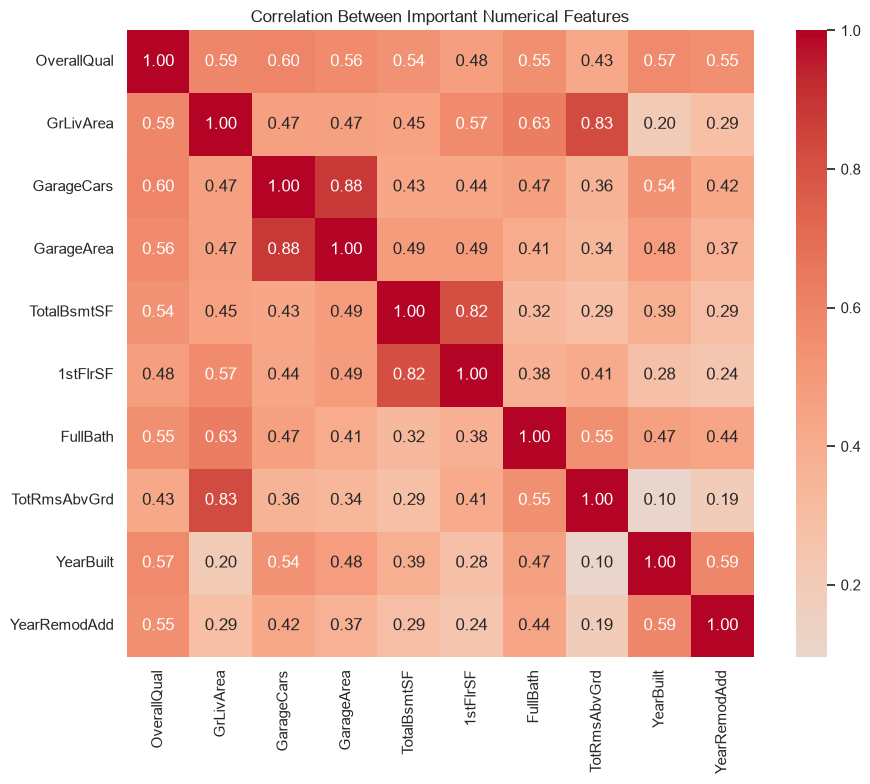

In [31]:
top_features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd",
]

plt.figure(figsize=(10, 8))

sns.heatmap(
    df[top_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Between Important Numerical Features")
plt.tight_layout()
plt.show()

In [32]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Number of categorical features:", len(categorical_cols))
print("\nCategorical features:")
print(categorical_cols)

Number of categorical features: 43

Categorical features:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


C:\Users\LOQ\AppData\Local\Temp\ipykernel_13888\1287042292.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


In [33]:
categorical_summary = pd.DataFrame({
    "Unique_Values": df[categorical_cols].nunique(),
    "Missing_Values": df[categorical_cols].isna().sum()
}).sort_values(
    "Unique_Values",
    ascending=False
)

display(categorical_summary)

,Unique_Values,Missing_Values
Neighborhood,25,0
Exterior2nd,16,0
Exterior1st,15,0
Condition1,9,0
SaleType,9,0
HouseStyle,8,0
RoofMatl,8,0
Condition2,8,0
Functional,7,0
BsmtFinType2,6,38


In [34]:
categorical_missing = (
    df[categorical_cols]
    .isna()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

missing_summary = pd.DataFrame({
    "Missing_Count": categorical_missing,
    "Missing_Percent": (
        categorical_missing / len(df) * 100
    ).round(2)
})

display(missing_summary)

,Missing_Count,Missing_Percent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
GarageFinish,81,5.55
GarageQual,81,5.55
GarageType,81,5.55
GarageCond,81,5.55


### Categorical Missing-Value Analysis

The dataset contains missing values across several categorical features. The largest missing-value counts occur in PoolQC (99.52%), MiscFeature (96.30%), Alley (93.77%), and Fence (80.75%). Earlier structural checks showed that missing pool quality, garage information, basement information, and fireplace quality can correspond to the absence of those features.

Missing values will therefore be handled according to their meaning. Confirmed structural absence will be represented explicitly, while genuinely unknown values will receive an appropriate imputation strategy. The treatment of each feature will be implemented within the model preprocessing pipeline to prevent data leakage during validation.

In [35]:
numeric_missing = (
    df.select_dtypes(include=np.number)
    .isna()
    .sum()
)

numeric_missing = numeric_missing[numeric_missing > 0].sort_values(
    ascending=False
)

numeric_missing_summary = pd.DataFrame({
    "Missing_Count": numeric_missing,
    "Missing_Percent": (
        numeric_missing / len(df) * 100
    ).round(2)
})

display(numeric_missing_summary)

,Missing_Count,Missing_Percent
LotFrontage,259,17.74
GarageYrBlt,81,5.55
MasVnrArea,8,0.55


In [36]:
print("GarageYrBlt missing:")
display(
    df.loc[
        df["GarageYrBlt"].isna(),
        ["Id", "GarageType", "GarageCars", "GarageArea", "GarageYrBlt"]
    ].head(10)
)

print("\nMasVnrArea missing:")
display(
    df.loc[
        df["MasVnrArea"].isna(),
        ["Id", "MasVnrType", "MasVnrArea", "SalePrice"]
    ]
)

GarageYrBlt missing:


,Id,GarageType,GarageCars,GarageArea,GarageYrBlt
39,40,NaN,0,0,NaN
48,49,NaN,0,0,NaN
78,79,NaN,0,0,NaN
88,89,NaN,0,0,NaN
89,90,NaN,0,0,NaN
99,100,NaN,0,0,NaN
108,109,NaN,0,0,NaN
125,126,NaN,0,0,NaN
127,128,NaN,0,0,NaN
140,141,NaN,0,0,NaN



MasVnrArea missing:


,Id,MasVnrType,MasVnrArea,SalePrice
234,235,NaN,NaN,216500
529,530,NaN,NaN,200624
650,651,NaN,NaN,205950
936,937,NaN,NaN,184900
973,974,NaN,NaN,182000
977,978,NaN,NaN,199900
1243,1244,NaN,NaN,465000
1278,1279,NaN,NaN,237000


### Numerical Missing-Value Investigation

The missing values in GarageYrBlt are associated with missing GarageType and zero values for GarageCars and GarageArea in the inspected records. This indicates that these properties likely do not have garages, so missing garage construction years represent structural absence.

All eight records with missing MasVnrArea also have missing MasVnrType. The available evidence does not conclusively establish whether masonry veneer is absent or its information is unknown. These values will therefore be handled conservatively during preprocessing, with any alternative assumptions evaluated through validation.

In [37]:
target = "SalePrice"

X = df.drop(columns=[target, "Id"])
y = df[target]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Numerical features:", len(X.select_dtypes(include=np.number).columns))
print("Categorical features:", len(X.select_dtypes(include=["object", "category"]).columns))
print("Target missing values:", y.isna().sum())

Feature matrix shape: (1460, 79)
Target shape: (1460,)
Numerical features: 36
Categorical features: 43
Target missing values: 0


C:\Users\LOQ\AppData\Local\Temp\ipykernel_13888\488241933.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("Categorical features:", len(X.select_dtypes(include=["object", "category"]).columns))


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)
print("Training target:", y_train.shape)
print("Validation target:", y_valid.shape)

Training features: (1168, 79)
Validation features: (292, 79)
Training target: (1168,)
Validation target: (292,)


In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Preprocessing pipeline created successfully.")

Numerical features: 36
Categorical features: 43
Preprocessing pipeline created successfully.


In [40]:
X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_valid_processed.shape)
print("Training matrix contains missing values:", 
      np.isnan(X_train_processed.toarray() if hasattr(X_train_processed, "toarray") 
               else X_train_processed).any())
print("Validation matrix contains missing values:", 
      np.isnan(X_valid_processed.toarray() if hasattr(X_valid_processed, "toarray") 
               else X_valid_processed).any())

Processed training shape: (1168, 285)
Processed validation shape: (292, 285)
Training matrix contains missing values: False
Validation matrix contains missing values: False


In [41]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

baseline_model = LinearRegression()
baseline_model.fit(X_train_processed, y_train)

y_pred_baseline = baseline_model.predict(X_valid_processed)

mae = mean_absolute_error(y_valid, y_pred_baseline)
rmse = np.sqrt(mean_squared_error(y_valid, y_pred_baseline))
r2 = r2_score(y_valid, y_pred_baseline)

print(f"Baseline Linear Regression Results")
print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")
print(f"R^2:    {r2:.4f}")

Baseline Linear Regression Results
MAE:  $20,466.13
RMSE: $31,294.99
R^2:    0.8723


### Baseline Model: Linear Regression

A Linear Regression model was trained using the preprocessed training data and evaluated on the held-out validation set. The model achieved an MAE of `$20,466.13`, an RMSE of `$31,294.99`, and an R^2 score of 0.8723.

These results provide a baseline for subsequent model comparisons. The validation metrics will be used to assess whether more flexible algorithms improve predictive accuracy. Final model selection will consider prediction errors, generalization, and suitability for deployment.

In [42]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

random_forest = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

random_forest.fit(X_train_processed, y_train)

y_pred_rf = random_forest.predict(X_valid_processed)

rf_mae = mean_absolute_error(y_valid, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_valid, y_pred_rf))
rf_r2 = r2_score(y_valid, y_pred_rf)

print("Random Forest Results")
print(f"MAE:  ${rf_mae:,.2f}")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"R^2:    {rf_r2:.4f}")

Random Forest Results
MAE:  $17,350.76
RMSE: $28,376.65
R^2:    0.8950


### Random Forest Model Evaluation

The Random Forest Regressor achieved an MAE of `$17,350.76`, an RMSE of `$28,376.65`, and an R^2 score of 0.8950 on the validation set. Compared with the Linear Regression baseline, MAE decreased by approximately 15.2%, RMSE decreased by approximately 9.3%, and R^2 increased from 0.8723 to 0.8950.

These results suggest that the Random Forest captures useful nonlinear relationships and feature interactions. It is the strongest model evaluated so far, but additional models and validation checks are required before making a final production recommendation.

In [43]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

gradient_boosting = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    loss="squared_error",
    random_state=42
)

gradient_boosting.fit(X_train_processed, y_train)

y_pred_gb = gradient_boosting.predict(X_valid_processed)

gb_mae = mean_absolute_error(y_valid, y_pred_gb)
gb_rmse = np.sqrt(mean_squared_error(y_valid, y_pred_gb))
gb_r2 = r2_score(y_valid, y_pred_gb)

print("Gradient Boosting Results")
print(f"MAE:  ${gb_mae:,.2f}")
print(f"RMSE: ${gb_rmse:,.2f}")
print(f"R^2:    {gb_r2:.4f}")

Gradient Boosting Results
MAE:  $16,946.24
RMSE: $27,667.91
R^2:    0.9002


### Gradient Boosting Model Evaluation

The Gradient Boosting Regressor achieved an MAE of `$16,946.24`, an RMSE of `$27,667.91`, and an R^2 score of 0.9002 on the validation set. It outperformed both Linear Regression and Random Forest on all three reported metrics.

Compared with the Linear Regression baseline, Gradient Boosting reduced MAE by approximately 17.2%. These results suggest that sequential tree-based learning captures useful nonlinear patterns in the dataset. Further validation, error analysis, and model comparison are needed before selecting the final model for production.

In [44]:
model_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(y_valid, y_pred_baseline),
        "RMSE": np.sqrt(mean_squared_error(y_valid, y_pred_baseline)),
        "R2": r2_score(y_valid, y_pred_baseline)
    },
    {
        "Model": "Random Forest",
        "MAE": mean_absolute_error(y_valid, y_pred_rf),
        "RMSE": np.sqrt(mean_squared_error(y_valid, y_pred_rf)),
        "R2": r2_score(y_valid, y_pred_rf)
    },
    {
        "Model": "Gradient Boosting",
        "MAE": mean_absolute_error(y_valid, y_pred_gb),
        "RMSE": np.sqrt(mean_squared_error(y_valid, y_pred_gb)),
        "R2": r2_score(y_valid, y_pred_gb)
    }
]).sort_values("MAE")

display(model_comparison.round(4))

,Model,MAE,RMSE,R2
2,Gradient Boosting,"16,946.24","27,667.91",0.90
1,Random Forest,"17,350.76","28,376.65",0.90
0,Linear Regression,"20,466.13","31,294.99",0.87


In [45]:
prediction_analysis = pd.DataFrame({
    "Actual_Price": y_valid,
    "Predicted_Price": y_pred_gb
})

prediction_analysis["Error"] = (
    prediction_analysis["Predicted_Price"]
    - prediction_analysis["Actual_Price"]
)

prediction_analysis["Absolute_Error"] = (
    prediction_analysis["Error"].abs()
)

display(
    prediction_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .round(2)
)

,Actual_Price,Predicted_Price,Error,Absolute_Error
898,611657,"398,807.10","-212,849.90","212,849.90"
581,253293,"376,132.94","122,839.94","122,839.94"
1046,556581,"434,234.36","-122,346.64","122,346.64"
691,755000,"637,823.37","-117,176.63","117,176.63"
774,395000,"286,778.33","-108,221.67","108,221.67"
218,311500,"222,626.67","-88,873.33","88,873.33"
261,276000,"354,641.11","78,641.11","78,641.11"
588,143000,"209,567.64","66,567.64","66,567.64"
1243,465000,"402,868.08","-62,131.92","62,131.92"
1024,287000,"345,271.75","58,271.75","58,271.75"


In [46]:
worst_indices = (
    prediction_analysis["Absolute_Error"]
    .nlargest(10)
    .index
)

worst_predictions = prediction_analysis.loc[worst_indices].copy()

worst_predictions["Id"] = df.loc[worst_indices, "Id"]
worst_predictions["OverallQual"] = df.loc[worst_indices, "OverallQual"]
worst_predictions["GrLivArea"] = df.loc[worst_indices, "GrLivArea"]
worst_predictions["YearBuilt"] = df.loc[worst_indices, "YearBuilt"]
worst_predictions["Neighborhood"] = df.loc[worst_indices, "Neighborhood"]

display(
    worst_predictions[
        [
            "Id",
            "Actual_Price",
            "Predicted_Price",
            "Error",
            "Absolute_Error",
            "OverallQual",
            "GrLivArea",
            "YearBuilt",
            "Neighborhood"
        ]
    ]
    .sort_values("Absolute_Error", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

,Id,Actual_Price,Predicted_Price,Error,Absolute_Error,OverallQual,GrLivArea,YearBuilt,Neighborhood
0,899,611657,"398,807.10","-212,849.90","212,849.90",9,2364,2009,NridgHt
1,582,253293,"376,132.94","122,839.94","122,839.94",8,2042,2008,NridgHt
2,1047,556581,"434,234.36","-122,346.64","122,346.64",9,2868,2005,StoneBr
3,692,755000,"637,823.37","-117,176.63","117,176.63",10,4316,1994,NoRidge
4,775,395000,"286,778.33","-108,221.67","108,221.67",8,1973,2006,NridgHt
5,219,311500,"222,626.67","-88,873.33","88,873.33",7,1954,1939,Crawfor
6,262,276000,"354,641.11","78,641.11","78,641.11",8,2574,2007,CollgCr
7,589,143000,"209,567.64","66,567.64","66,567.64",5,1473,1968,ClearCr
8,1244,465000,"402,868.08","-62,131.92","62,131.92",10,2076,2006,NridgHt
9,1025,287000,"345,271.75","58,271.75","58,271.75",8,2898,1976,Timber


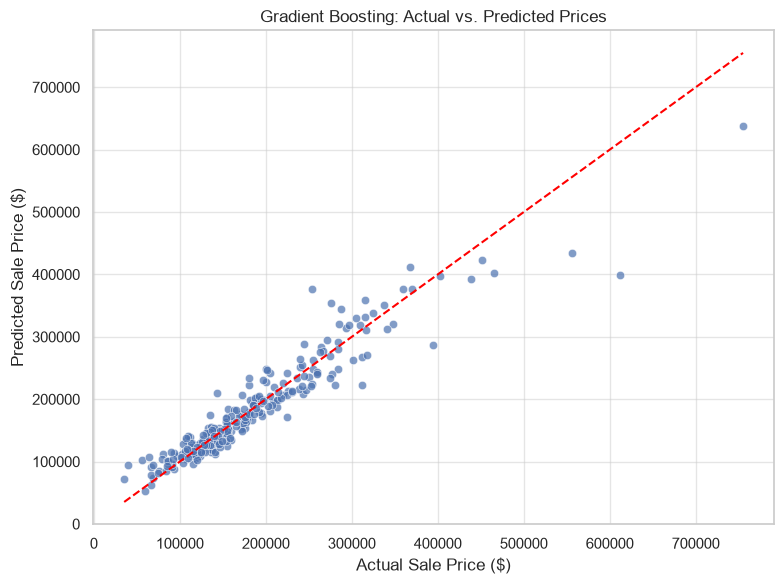

In [47]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_valid,
    y=y_pred_gb,
    alpha=0.7
)

min_price = min(y_valid.min(), y_pred_gb.min())
max_price = max(y_valid.max(), y_pred_gb.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    color="red"
)

plt.title("Gradient Boosting: Actual vs. Predicted Prices")
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

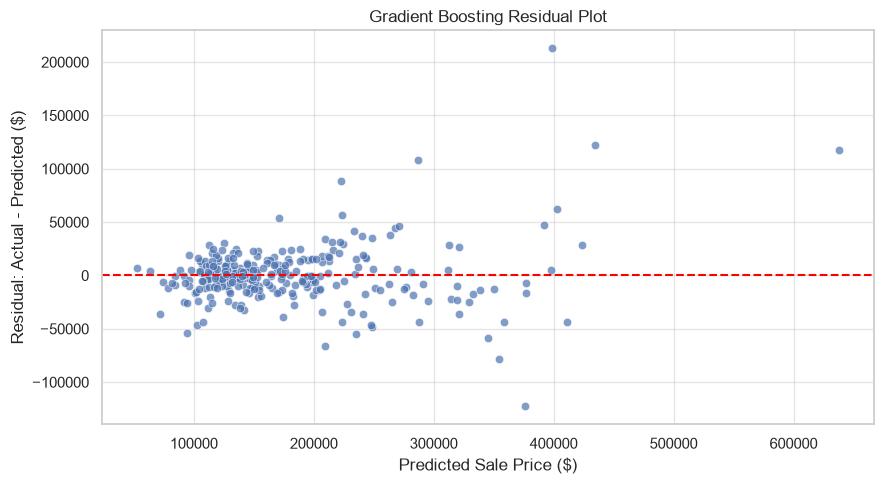

In [48]:
residuals = y_valid - y_pred_gb

plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=y_pred_gb,
    y=residuals,
    alpha=0.7
)

plt.axhline(0, linestyle="--", color="red")

plt.title("Gradient Boosting Residual Plot")
plt.xlabel("Predicted Sale Price ($)")
plt.ylabel("Residual: Actual - Predicted ($)")
plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

In [49]:
residual_analysis = pd.DataFrame({
    "Actual_Price": y_valid,
    "Predicted_Price": y_pred_gb,
    "Residual": y_valid - y_pred_gb
})

residual_analysis["Price_Range"] = pd.cut(
    residual_analysis["Actual_Price"],
    bins=[0, 100000, 200000, 300000, 500000, float("inf")],
    labels=["Under $100k", "$100k to $200k", "$200k to $300k",
            "$300k to $500k", "Over $500k"]
)

display(
    residual_analysis.groupby("Price_Range", observed=True)["Residual"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

,count,mean,median,std
Price_Range,,,,
Under $100k,26,"-16,472.55","-12,201.88","16,148.77"
$100k to $200k,184,-869.82,85.76,"14,412.03"
$200k to $300k,58,42.42,"6,718.40","32,082.26"
$300k to $500k,21,"16,262.44","5,512.10","40,975.22"
Over $500k,3,"150,791.06","122,346.64","53,806.67"


In [50]:
residual_analysis["Price_Range"] = pd.cut(
    residual_analysis["Actual_Price"],
    bins=[0, 100000, 200000, 300000, 500000, float("inf")],
    labels=[
        "Under $100k",
        "$100k to $200k",
        "$200k to $300k",
        "$300k to $500k",
        "Over $500k"
    ],
    include_lowest=True
)

residual_summary = (
    residual_analysis.groupby("Price_Range", observed=False)
    .agg(
        House_Count=("Residual", "count"),
        Mean_Residual=("Residual", "mean"),
        Median_Residual=("Residual", "median"),
        Residual_Std=("Residual", "std")
    )
    .round(2)
)

display(residual_summary)

,House_Count,Mean_Residual,Median_Residual,Residual_Std
Price_Range,,,,
Under $100k,26,"-16,472.55","-12,201.88","16,148.77"
$100k to $200k,184,-869.82,85.76,"14,412.03"
$200k to $300k,58,42.42,"6,718.40","32,082.26"
$300k to $500k,21,"16,262.44","5,512.10","40,975.22"
Over $500k,3,"150,791.06","122,346.64","53,806.67"


In [51]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Transform the training target
y_train_log = np.log1p(y_train)

# Train on log-transformed prices
gradient_boosting_log = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    loss="squared_error",
    random_state=42
)

gradient_boosting_log.fit(X_train_processed, y_train_log)

# Predict in log space, then convert back to dollars
y_pred_log = gradient_boosting_log.predict(X_valid_processed)
y_pred_log_dollars = np.expm1(y_pred_log)

# Evaluate in original dollar units
log_mae = mean_absolute_error(y_valid, y_pred_log_dollars)
log_rmse = np.sqrt(mean_squared_error(y_valid, y_pred_log_dollars))
log_r2 = r2_score(y_valid, y_pred_log_dollars)

print("Gradient Boosting with Log-Transformed Target")
print(f"MAE:  ${log_mae:,.2f}")
print(f"RMSE: ${log_rmse:,.2f}")
print(f"R^2:    {log_r2:.4f}")

Gradient Boosting with Log-Transformed Target
MAE:  $16,702.71
RMSE: $30,406.13
R^2:    0.8795


### Experiment: Log-Transformed Target

A Gradient Boosting model was trained using `log1p(SalePrice)`, and its predictions were converted back to dollars using `expm1` before evaluation. The model achieved an MAE of `$16,702.71`, an RMSE of `$30,406.13`, and an R^2 score of 0.8795.

Compared with the original-target Gradient Boosting model, the log-target experiment slightly reduced MAE but increased RMSE and reduced R^2. This indicates a trade-off between typical absolute error and the penalty assigned to larger errors. The original-target model remains the leading candidate pending further validation and model comparison.

In [52]:
model_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "MAE": mean_absolute_error(y_valid, y_pred_baseline),
        "RMSE": np.sqrt(mean_squared_error(y_valid, y_pred_baseline)),
        "R2": r2_score(y_valid, y_pred_baseline)
    },
    {
        "Model": "Random Forest",
        "MAE": mean_absolute_error(y_valid, y_pred_rf),
        "RMSE": np.sqrt(mean_squared_error(y_valid, y_pred_rf)),
        "R2": r2_score(y_valid, y_pred_rf)
    },
    {
        "Model": "Gradient Boosting (Original Target)",
        "MAE": mean_absolute_error(y_valid, y_pred_gb),
        "RMSE": np.sqrt(mean_squared_error(y_valid, y_pred_gb)),
        "R2": r2_score(y_valid, y_pred_gb)
    },
    {
        "Model": "Gradient Boosting (Log Target)",
        "MAE": mean_absolute_error(y_valid, y_pred_log_dollars),
        "RMSE": np.sqrt(mean_squared_error(y_valid, y_pred_log_dollars)),
        "R2": r2_score(y_valid, y_pred_log_dollars)
    }
]).sort_values("MAE").reset_index(drop=True)

display(model_comparison.round(4))

,Model,MAE,RMSE,R2
0,Gradient Boosting (Log Target),"16,702.71","30,406.13",0.88
1,Gradient Boosting (Original Target),"16,946.24","27,667.91",0.90
2,Random Forest,"17,350.76","28,376.65",0.90
3,Linear Regression,"20,466.13","31,294.99",0.87


In [53]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor

cv_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        loss="squared_error",
        random_state=42
    ))
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1,
    return_train_score=False
)

print(f"Mean CV MAE:  ${-cv_results['test_mae'].mean():,.2f}")
print(f"Mean CV RMSE: ${-cv_results['test_rmse'].mean():,.2f}")
print(f"Mean CV R^2:    {cv_results['test_r2'].mean():.4f}")

print(f"MAE standard deviation:  ${cv_results['test_mae'].std():,.2f}")
print(f"RMSE standard deviation: ${cv_results['test_rmse'].std():,.2f}")
print(f"R^2 standard deviation:    {cv_results['test_r2'].std():.4f}")

Mean CV MAE:  $16,027.75
Mean CV RMSE: $28,161.69
Mean CV R^2:    0.8607
MAE standard deviation:  $1,680.33
RMSE standard deviation: $7,054.44
R^2 standard deviation:    0.0649


### Five-Fold Cross-Validation

The Gradient Boosting model was evaluated using five-fold cross-validation on the training partition. The mean MAE was `$16,027.75`, mean RMSE was `$28,161.69`, and mean R^2 was 0.8607.

The standard deviations were `$1,680.33` for MAE, `$7,054.44` for RMSE, and 0.0649 for R^2. These results indicate variation in predictive performance across folds, with RMSE showing comparatively high variability. Cross-validation provides a more robust assessment than relying on a single split, although further validation and careful preprocessing are needed before final model selection.

In [54]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

fresh_numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

fresh_categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

fresh_preprocessor = ColumnTransformer([
    ("num", fresh_numeric_transformer, numeric_features),
    ("cat", fresh_categorical_transformer, categorical_features)
])

clean_cv_pipeline = Pipeline([
    ("preprocessor", fresh_preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

print("Fresh preprocessing pipeline created.")
print("Preprocessing will be fitted separately within each CV fold.")

Fresh preprocessing pipeline created.
Preprocessing will be fitted separately within each CV fold.


C:\Users\LOQ\AppData\Local\Temp\ipykernel_13888\127933773.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [55]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

clean_cv_results = cross_validate(
    clean_cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1,
    return_train_score=False
)

print("Clean Five-Fold Cross-Validation Results")
print(
    f"Mean CV MAE:  "
    f"${-clean_cv_results['test_mae'].mean():,.2f}"
)
print(
    f"Mean CV RMSE: "
    f"${-clean_cv_results['test_rmse'].mean():,.2f}"
)
print(
    f"Mean CV R^2:    "
    f"{clean_cv_results['test_r2'].mean():.4f}"
)

print(
    f"MAE standard deviation:  "
    f"${clean_cv_results['test_mae'].std():,.2f}"
)
print(
    f"RMSE standard deviation: "
    f"${clean_cv_results['test_rmse'].std():,.2f}"
)
print(
    f"R^2 standard deviation:    "
    f"{clean_cv_results['test_r2'].std():.4f}"
)

Clean Five-Fold Cross-Validation Results
Mean CV MAE:  $16,027.75
Mean CV RMSE: $28,161.69
Mean CV R^2:    0.8607
MAE standard deviation:  $1,680.33
RMSE standard deviation: $7,054.44
R^2 standard deviation:    0.0649


In [56]:
tuned_gb_pipeline = Pipeline([
    ("preprocessor", fresh_preprocessor),
    ("model", GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=2,
        min_samples_leaf=5,
        loss="squared_error",
        random_state=42
    ))
])

tuned_cv_results = cross_validate(
    tuned_gb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2": "r2"
    },
    n_jobs=-1,
    return_train_score=False
)

print("Tuned Gradient Boosting | Five-Fold CV")
print(f"Mean CV MAE:  ${-tuned_cv_results['test_mae'].mean():,.2f}")
print(f"Mean CV RMSE: ${-tuned_cv_results['test_rmse'].mean():,.2f}")
print(f"Mean CV R^2:    {tuned_cv_results['test_r2'].mean():.4f}")

Tuned Gradient Boosting | Five-Fold CV
Mean CV MAE:  $17,841.26
Mean CV RMSE: $30,455.70
Mean CV R^2:    0.8408


### Gradient Boosting Hyperparameter Experiment

A second Gradient Boosting configuration was evaluated using five-fold cross-validation with 300 estimators, a learning rate of 0.03, a maximum tree depth of 2, and a minimum leaf size of 5.

The tuned model achieved a mean MAE of `$17,841.26`, mean RMSE of `$30,455.70`, and mean R^2 of 0.8408. These results were worse than the original configuration, which achieved a mean MAE of `$16,027.75`, mean RMSE of `$28,161.69`, and mean R^2 of 0.8607.

This experiment demonstrates that increasing the number of estimators and reducing tree complexity did not improve performance with the tested settings. The original Gradient Boosting configuration remains preferred among these two configurations.

In [57]:
fold_comparison = pd.DataFrame({
    "Fold": range(1, 6),
    "Original_MAE": -clean_cv_results["test_mae"],
    "Tuned_MAE": -tuned_cv_results["test_mae"],
    "Original_RMSE": -clean_cv_results["test_rmse"],
    "Tuned_RMSE": -tuned_cv_results["test_rmse"],
    "Original_R2": clean_cv_results["test_r2"],
    "Tuned_R2": tuned_cv_results["test_r2"]
})

display(fold_comparison.round(4))

,Fold,Original_MAE,Tuned_MAE,Original_RMSE,Tuned_RMSE,Original_R2,Tuned_R2
0,1,"15,150.56","16,927.10","24,614.03","27,663.75",0.91,0.88
1,2,"17,490.35","19,847.75","37,819.20","37,729.20",0.76,0.76
2,3,"18,310.22","19,166.56","35,420.61","36,246.44",0.81,0.80
3,4,"15,565.08","17,764.42","22,155.02","26,595.01",0.91,0.87
4,5,"13,622.52","15,500.47","20,799.60","24,044.11",0.92,0.89


### Fold-Level Cross-Validation Analysis

The fold-level comparison showed that the original Gradient Boosting configuration achieved a lower MAE than the tuned configuration in all five folds. It also achieved a lower RMSE in four out of five folds and higher R^2 in four folds, with approximately equal R^2 in the remaining fold based on the displayed rounded values.

The tuned configuration therefore did not demonstrate a consistent improvement in predictive performance. The original configuration, using 200 estimators, a learning rate of 0.05, and a maximum tree depth of 3, will be retained as the leading Gradient Boosting candidate for subsequent evaluation.

Cross-validation results will be considered alongside validation-set performance before selecting the final production candidate.

In [58]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

models_to_compare = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        loss="squared_error",
        random_state=42
    )
}

comparison_results = []

for model_name, model in models_to_compare.items():
    pipeline = Pipeline([
        ("preprocessor", fresh_preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2"
        },
        n_jobs=-1,
        return_train_score=False
    )

    comparison_results.append({
        "Model": model_name,
        "Mean CV MAE": -scores["test_mae"].mean(),
        "Mean CV RMSE": -scores["test_rmse"].mean(),
        "Mean CV R2": scores["test_r2"].mean(),
        "MAE Std": scores["test_mae"].std()
    })

cv_model_comparison = pd.DataFrame(comparison_results)
display(cv_model_comparison.round(4))

,Model,Mean CV MAE,Mean CV RMSE,Mean CV R2,MAE Std
0,Random Forest,"18,143.70","30,264.36",0.84,"1,106.92"
1,Gradient Boosting,"16,027.75","28,161.69",0.86,"1,680.33"


### Random Forest vs. Gradient Boosting

Random Forest and Gradient Boosting were compared using five-fold cross-validation on the training partition, with the same preprocessing approach and evaluation metrics.

Gradient Boosting achieved a mean CV MAE of `$16,027.75`, mean CV RMSE of `$28,161.69`, and mean R^2 of approximately 0.86. Random Forest achieved a mean CV MAE of `$18,143.70`, mean CV RMSE of `$30,264.36`, and mean R^2 of approximately 0.84.

Gradient Boosting reduced mean MAE by approximately 11.7% and mean RMSE by approximately 6.9% relative to Random Forest. However, Random Forest had lower fold-to-fold MAE standard deviation, indicating more consistent MAE across the five validation folds.

Based on the current cross-validation results, Gradient Boosting is the leading candidate. The final decision will also consider validation-set performance, model complexity, and prediction error patterns.

In [59]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

validation_models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        loss="squared_error",
        random_state=42
    )
}

validation_results = []
fitted_validation_models = {}

for model_name, model in validation_models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(fresh_preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_valid)

    fitted_validation_models[model_name] = pipeline

    validation_results.append({
        "Model": model_name,
        "Validation MAE": mean_absolute_error(y_valid, predictions),
        "Validation RMSE": root_mean_squared_error(y_valid, predictions),
        "Validation R2": r2_score(y_valid, predictions)
    })

validation_comparison = pd.DataFrame(validation_results)
display(validation_comparison.round(4))

,Model,Validation MAE,Validation RMSE,Validation R2
0,Random Forest,"17,350.76","28,376.65",0.90
1,Gradient Boosting,"16,946.24","27,667.91",0.90


### Validation-Set Model Comparison

The Random Forest and Gradient Boosting models were fitted using the training partition and evaluated on the held-out validation partition.

Random Forest achieved a validation MAE of `$17,350.76`, RMSE of `$28,376.65`, and R^2 of approximately 0.8950. Gradient Boosting achieved a validation MAE of `$16,946.24`, RMSE of `$27,667.91`, and R^2 of approximately 0.9002.

Gradient Boosting reduced validation MAE by approximately 2.33% and RMSE by approximately 2.50% relative to Random Forest. It also achieved a slightly higher R^2. These results agree with the five-fold cross-validation comparison, in which Gradient Boosting had lower average MAE and RMSE.

Therefore, Gradient Boosting is selected as the leading candidate for the final model, subject to the remaining diagnostic checks and completion of the model comparison report.

In [60]:
best_model = fitted_validation_models["Gradient Boosting"]

gb_validation_predictions = best_model.predict(X_valid)

validation_diagnostics = pd.DataFrame({
    "ActualPrice": y_valid.to_numpy(),
    "PredictedPrice": gb_validation_predictions,
    "Residual": y_valid.to_numpy() - gb_validation_predictions
})

validation_diagnostics["AbsoluteError"] = (
    validation_diagnostics["Residual"].abs()
)

print("Largest absolute prediction errors:")
display(
    validation_diagnostics
    .sort_values("AbsoluteError", ascending=False)
    .head(10)
    .round(2)
)

print("\nResidual summary:")
display(
    validation_diagnostics["Residual"]
    .describe()
    .round(2)
)

Largest absolute prediction errors:


,ActualPrice,PredictedPrice,Residual,AbsoluteError
74,611657,"398,807.10","212,849.90","212,849.90"
43,253293,"376,132.94","-122,839.94","122,839.94"
168,556581,"434,234.36","122,346.64","122,346.64"
139,755000,"637,823.37","117,176.63","117,176.63"
260,395000,"286,778.33","108,221.67","108,221.67"
6,311500,"222,626.67","88,873.33","88,873.33"
167,276000,"354,641.11","-78,641.11","78,641.11"
278,143000,"209,567.64","-66,567.64","66,567.64"
270,465000,"402,868.08","62,131.92","62,131.92"
53,287000,"345,271.75","-58,271.75","58,271.75"



Residual summary:


count        292.00
mean         712.37
std       27,706.23
min     -122,839.94
25%      -11,142.10
50%          -89.92
75%       10,809.63
max      212,849.90
Name: Residual, dtype: float64

### Residual Analysis and Model Limitations

The Gradient Boosting model was evaluated using residuals on the held-out validation set of 292 houses. The mean residual was `$712.37`, while the median residual was `$89.92`. These values indicate that the model's overall signed error was close to zero, although individual predictions varied considerably.

The validation set contained substantial prediction errors. The largest underprediction was `$212,849.90` for a house with an actual price of `$611,657`. The largest overprediction was `$122,839.94` for a house with an actual price of `$253,293`. Several other properties had absolute errors exceeding `$100,000`.

The validation MAE was `$16,946.24` and the RMSE was `$27,667.91`. The higher RMSE relative to MAE indicates that a small number of large errors materially affect model performance.

These results suggest that the model is useful for estimating house prices overall but is less reliable for certain individual properties, particularly some high-priced homes. The large errors should be investigated using property features and prediction diagnostics. They should not be removed automatically without evidence of data errors or a justified modeling reason.

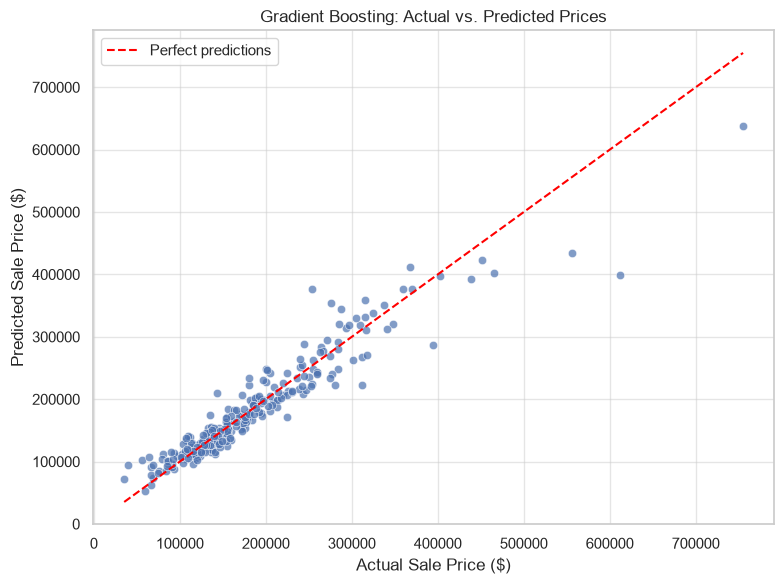

In [61]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=validation_diagnostics["ActualPrice"],
    y=validation_diagnostics["PredictedPrice"],
    alpha=0.7
)

min_price = min(
    validation_diagnostics["ActualPrice"].min(),
    validation_diagnostics["PredictedPrice"].min()
)
max_price = max(
    validation_diagnostics["ActualPrice"].max(),
    validation_diagnostics["PredictedPrice"].max()
)

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    color="red",
    label="Perfect predictions"
)

plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title("Gradient Boosting: Actual vs. Predicted Prices")
plt.legend()
plt.tight_layout()
plt.show()

### Actual vs. Predicted Price Analysis

The actual-versus-predicted scatter plot shows that most predictions are relatively close to the reference line representing perfect predictions. This indicates that the Gradient Boosting model captures the overall relationship between property features and sale prices reasonably well.

However, some observations deviate substantially from the reference line, indicating larger prediction errors for individual properties. Therefore, the model demonstrates good overall predictive performance but should be used cautiously for properties with unusual characteristics or very high prices.

,Feature,Importance
3,num__OverallQual,0.51
15,num__GrLivArea,0.15
25,num__GarageCars,0.05
11,num__TotalBsmtSF,0.04
8,num__BsmtFinSF1,0.04
13,num__2ndFlrSF,0.03
12,num__1stFlrSF,0.03
2,num__LotArea,0.02
245,cat__GarageFinish_Unf,0.02
180,cat__BsmtQual_Ex,0.01


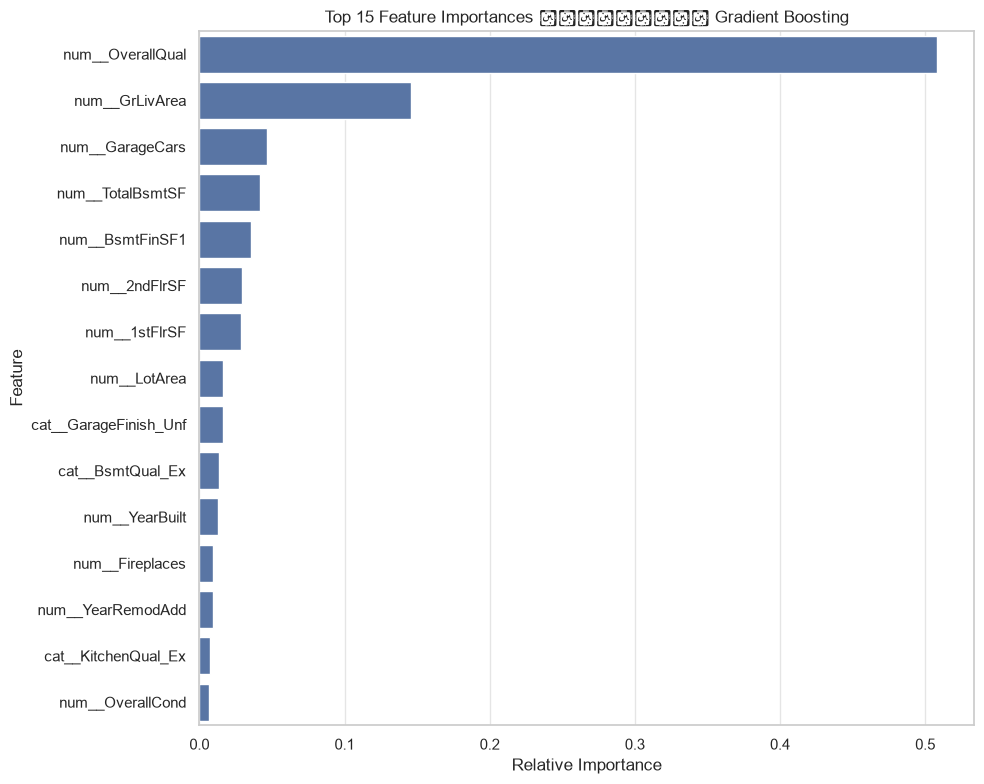

In [62]:
feature_importance = pd.DataFrame({
    "Feature": best_model.named_steps["preprocessor"].get_feature_names_out(),
    "Importance": best_model.named_steps["model"].feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance", ascending=False
)

display(feature_importance.head(20).round(4))

plt.figure(figsize=(10, 8))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Gradient Boosting Feature Importances")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [63]:
neighborhood_analysis = (
    df.groupby("Neighborhood")
    .agg(
        House_Count=("SalePrice", "count"),
        Median_Price=("SalePrice", "median"),
        Average_Price=("SalePrice", "mean"),
        Minimum_Price=("SalePrice", "min"),
        Maximum_Price=("SalePrice", "max")
    )
    .sort_values("Median_Price")
    .reset_index()
)

display(
    neighborhood_analysis.style.format({
        "Median_Price": "${:,.0f}",
        "Average_Price": "${:,.0f}",
        "Minimum_Price": "${:,.0f}",
        "Maximum_Price": "${:,.0f}"
    })
)

,Neighborhood,House_Count,Median_Price,Average_Price,Minimum_Price,Maximum_Price
0,MeadowV,17,"$88,000","$98,576","$75,000","$151,400"
1,IDOTRR,37,"$103,000","$100,124","$34,900","$169,500"
2,BrDale,16,"$106,000","$104,494","$83,000","$125,000"
3,OldTown,113,"$119,000","$128,225","$37,900","$475,000"
4,Edwards,100,"$121,750","$128,220","$58,500","$320,000"
5,BrkSide,58,"$124,300","$124,834","$39,300","$223,500"
6,Sawyer,74,"$135,000","$136,793","$62,383","$190,000"
7,Blueste,2,"$137,500","$137,500","$124,000","$151,000"
8,SWISU,25,"$139,500","$142,591","$60,000","$200,000"
9,NAmes,225,"$140,000","$145,847","$87,500","$345,000"


### Neighborhood-Based Buyer Analysis

Neighborhood-level price analysis reveals substantial variation in house prices across locations.

MeadowV has the lowest median sale price of `$88,000`, followed by IDOTRR at `$103,000` and BrDale at `$106,000`. These neighborhoods represent relatively affordable options within the dataset.

At the premium end, NridgHt has the highest median price of `$315,000`, followed by NoRidge at `$301,500` and StoneBr at `$278,000`.

NAmes contains the largest number of observations (225), providing a comparatively larger sample for neighborhood-level analysis. In contrast, Blueste has only two observations, so its median price should be interpreted cautiously.

The price ranges within several neighborhoods are wide, indicating that property characteristics such as quality, living area, condition, and amenities also influence sale prices. Therefore, buyers should consider both neighborhood and individual property characteristics rather than relying exclusively on neighborhood median prices.

These findings describe the historical dataset and should not be interpreted as current market quotations.

In [64]:
buyer_budgets = {
    "Budget Buyer": 125000,
    "Mid-Range Buyer": 200000,
    "Premium Buyer": 350000
}

buyer_recommendations = []

for buyer_type, budget in buyer_budgets.items():
    eligible = neighborhood_analysis[
        neighborhood_analysis["Median_Price"] <= budget
    ].copy()

    buyer_recommendations.append({
        "Buyer Type": buyer_type,
        "Maximum Budget": budget,
        "Suitable Neighborhoods": ", ".join(
            eligible["Neighborhood"].tolist()
        ),
        "Number of Neighborhoods": len(eligible)
    })

buyer_recommendations_df = pd.DataFrame(buyer_recommendations)

display(buyer_recommendations_df)

,Buyer Type,Maximum Budget,Suitable Neighborhoods,Number of Neighborhoods
0,Budget Buyer,125000,"MeadowV, IDOTRR, BrDale, OldTown, Edwards, Brk...",6
1,Mid-Range Buyer,200000,"MeadowV, IDOTRR, BrDale, OldTown, Edwards, Brk...",17
2,Premium Buyer,350000,"MeadowV, IDOTRR, BrDale, OldTown, Edwards, Brk...",25


In [65]:
buyer_profiles = {
    "Budget Buyer": {
        "budget": 125000,
        "min_quality": 5,
        "min_living_area": 1000,
        "min_bedrooms": 2,
        "min_bathrooms": 1
    },
    "Mid-Range Buyer": {
        "budget": 200000,
        "min_quality": 6,
        "min_living_area": 1400,
        "min_bedrooms": 3,
        "min_bathrooms": 2
    },
    "Premium Buyer": {
        "budget": 350000,
        "min_quality": 8,
        "min_living_area": 1800,
        "min_bedrooms": 3,
        "min_bathrooms": 2
    }
}

buyer_property_recommendations = {}

for buyer_type, requirements in buyer_profiles.items():
    suitable_houses = df[
        (df["SalePrice"] <= requirements["budget"]) &
        (df["OverallQual"] >= requirements["min_quality"]) &
        (df["GrLivArea"] >= requirements["min_living_area"]) &
        (df["BedroomAbvGr"] >= requirements["min_bedrooms"]) &
        (df["FullBath"] >= requirements["min_bathrooms"])
    ].copy()

    buyer_property_recommendations[buyer_type] = suitable_houses

    print(f"\n{buyer_type}")
    print("Matching properties:", len(suitable_houses))

    display(
        suitable_houses[
            [
                "Id",
                "Neighborhood",
                "SalePrice",
                "OverallQual",
                "GrLivArea",
                "BedroomAbvGr",
                "FullBath"
            ]
        ].head(10)
    )


Budget Buyer
Matching properties: 115


,Id,Neighborhood,SalePrice,OverallQual,GrLivArea,BedroomAbvGr,FullBath
9,10,BrkSide,118000,5,1077,2,1
38,39,NAmes,109000,5,1057,3,1
51,52,BrkSide,114500,6,1176,3,1
61,62,IDOTRR,101000,5,1111,3,1
79,80,OldTown,110000,5,1230,2,1
91,92,NAmes,98600,5,1235,2,1
102,103,SawyerW,118964,5,1535,4,2
108,109,IDOTRR,115000,5,1517,3,2
144,145,Sawyer,125000,5,1728,6,2
149,150,BrkSide,115000,5,1344,3,1



Mid-Range Buyer
Matching properties: 186


,Id,Neighborhood,SalePrice,OverallQual,GrLivArea,BedroomAbvGr,FullBath
7,8,NWAmes,200000,7,2090,3,2
50,51,Gilbert,177000,6,1470,3,2
55,56,NAmes,180500,6,1425,3,2
56,57,Somerst,172500,8,1739,3,2
57,58,CollgCr,196500,7,1720,3,2
63,64,OldTown,140000,7,1710,3,2
66,67,NAmes,180000,7,2207,3,2
72,73,Gilbert,185000,7,1718,3,2
80,81,NAmes,193500,6,2142,4,2
84,85,Gilbert,168500,7,1474,3,2



Premium Buyer
Matching properties: 79


,Id,Neighborhood,SalePrice,OverallQual,GrLivArea,BedroomAbvGr,FullBath
4,5,NoRidge,250000,8,2198,4,2
11,12,NridgHt,345000,9,2324,4,3
20,21,NridgHt,325300,8,2376,4,3
35,36,NridgHt,309000,8,2452,4,3
65,66,NridgHt,317000,8,2473,4,2
85,86,NoRidge,260000,8,2417,4,2
105,106,Somerst,250000,8,1992,3,2
138,139,CollgCr,230000,8,1852,3,2
157,158,Timber,269500,8,1968,4,2
190,191,Crawfor,315000,8,2727,3,2


### Buyer Recommendations Based on Budget and Property Requirements

A rule-based property recommendation analysis was performed using three illustrative buyer profiles. The filtering criteria included maximum sale price, minimum overall quality, minimum above-ground living area, minimum bedroom count, and minimum full bathrooms.

| Buyer Profile | Budget | Minimum Quality | Minimum Living Area | Bedrooms | Full Bathrooms | Matching Properties |
|---|---:|---:|---:|---:|---:|---:|
| Budget Buyer | `$125,000` | 5 | 1,000 sq. ft. | 2 | 1 | 115 |
| Mid-Range Buyer | `$200,000` | 6 | 1,400 sq. ft. | 3 | 2 | 186 |
| Premium Buyer | `$350,000` | 8 | 1,800 sq. ft. | 3 | 2 | 79 |

The Budget Buyer profile returned 115 matching properties, with examples in BrkSide, NAmes, IDOTRR, and OldTown. The Mid-Range Buyer profile returned 186 properties, including examples in NWAmes, Gilbert, Somerst, and CollgCr. The Premium Buyer profile returned 79 properties, with examples in NoRidge, NridgHt, Somerst, and Timber.

The results demonstrate how budget and property requirements can narrow a dataset into a more relevant selection of properties. The recommendation method is rule-based and uses historical sale prices and property characteristics. It is a demonstration rather than a live property recommendation service.

**Limitation:** Actual sale prices are available in this historical dataset. In a real-world application, the system would need to estimate the price of an unsold property using the trained prediction model before determining whether it fits a buyer's budget.

In [66]:
def rank_properties(houses, budget):
    ranked = houses.copy()

    ranked["Budget_Utilization"] = (
        ranked["SalePrice"] / budget
    )

    ranked["Quality_Score"] = (
        ranked["OverallQual"] / 10
    )

    ranked["Area_Score"] = (
        ranked["GrLivArea"] / ranked["GrLivArea"].max()
    )

    ranked["Recommendation_Score"] = (
        0.40 * (1 - ranked["Budget_Utilization"]) +
        0.40 * ranked["Quality_Score"] +
        0.20 * ranked["Area_Score"]
    )

    return ranked.sort_values(
        "Recommendation_Score",
        ascending=False
    )


for buyer_type, requirements in buyer_profiles.items():
    ranked = rank_properties(
        buyer_property_recommendations[buyer_type],
        requirements["budget"]
    )

    print(f"\nTop 5 recommendations for {buyer_type}")

    display(
        ranked[
            [
                "Id",
                "Neighborhood",
                "SalePrice",
                "OverallQual",
                "GrLivArea",
                "Recommendation_Score"
            ]
        ].head(5).round(3)
    )


Top 5 recommendations for Budget Buyer


,Id,Neighborhood,SalePrice,OverallQual,GrLivArea,Recommendation_Score
632,633,NWAmes,82500,7,1411,0.54
1349,1350,OldTown,122000,8,2358,0.53
410,411,Edwards,60000,5,1276,0.52
1062,1063,OldTown,90000,5,2337,0.51
812,813,IDOTRR,55993,5,1044,0.51



Top 5 recommendations for Mid-Range Buyer


,Id,Neighborhood,SalePrice,OverallQual,GrLivArea,Recommendation_Score
1298,1299,Edwards,160000,10,5642,0.68
523,524,Edwards,184750,10,4676,0.60
632,633,NWAmes,82500,7,1411,0.56
1349,1350,OldTown,122000,8,2358,0.56
1216,1217,Sawyer,112000,6,1902,0.48



Top 5 recommendations for Premium Buyer


,Id,Neighborhood,SalePrice,OverallQual,GrLivArea,Recommendation_Score
1298,1299,Edwards,160000,10,5642,0.82
523,524,Edwards,184750,10,4676,0.76
1349,1350,OldTown,122000,8,2358,0.66
197,198,NAmes,235000,8,3112,0.56
340,341,Timber,202900,8,1908,0.56


In [67]:
unusual_property_ids = [1299, 524]

columns_to_inspect = [
    "Id",
    "Neighborhood",
    "SalePrice",
    "OverallQual",
    "OverallCond",
    "GrLivArea",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "TotRmsAbvGrd",
    "BedroomAbvGr",
    "FullBath",
    "HalfBath",
    "YearBuilt",
    "YearRemodAdd",
    "SaleCondition"
]

display(
    df.loc[
        df["Id"].isin(unusual_property_ids),
        columns_to_inspect
    ].T
)

,523,1298
Id,524,1299
Neighborhood,Edwards,Edwards
SalePrice,184750,160000
OverallQual,10,10
OverallCond,5,5
GrLivArea,4676,5642
1stFlrSF,3138,4692
2ndFlrSF,1538,950
LowQualFinSF,0,0
TotRmsAbvGrd,11,12


In [68]:
display(
    df.groupby("SaleCondition")
    .agg(
        Property_Count=("Id", "count"),
        Median_Price=("SalePrice", "median"),
        Mean_Price=("SalePrice", "mean"),
        Median_Living_Area=("GrLivArea", "median"),
        Mean_Living_Area=("GrLivArea", "mean")
    )
    .sort_values("Median_Price", ascending=False)
    .round(2)
)

,Property_Count,Median_Price,Mean_Price,Median_Living_Area,Mean_Living_Area
SaleCondition,,,,,
Partial,125,"244,600.00","272,291.75","1,646.00","1,795.70"
Normal,1198,"160,000.00","175,202.22","1,456.00","1,492.97"
Alloca,12,"148,145.00","167,377.42","1,439.50","1,701.75"
Family,20,"140,500.00","149,600.00","1,390.50","1,480.95"
Abnorml,101,"130,000.00","146,526.62","1,302.00","1,436.13"
AdjLand,4,"104,000.00","104,125.00","1,143.00","1,112.50"


In [69]:
partial_sales = df[df["SaleCondition"] == "Partial"].copy()

partial_sales["PricePerSqFt"] = (
    partial_sales["SalePrice"] / partial_sales["GrLivArea"]
)

display(
    partial_sales["PricePerSqFt"]
    .describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
    .round(2)
)

display(
    partial_sales.loc[
        partial_sales["Id"].isin([524, 1299]),
        ["Id", "SalePrice", "GrLivArea", "PricePerSqFt"]
    ].round(2)
)

count   125.00
mean    153.68
std      37.05
min      28.36
5%      108.01
25%     132.68
50%     148.82
75%     174.70
95%     217.38
max     276.25
Name: PricePerSqFt, dtype: float64

,Id,SalePrice,GrLivArea,PricePerSqFt
523,524,184750,4676,39.51
1298,1299,160000,5642,28.36


In [70]:
display(
    df[df["SaleCondition"] == "Partial"]
    .groupby("SaleType")
    .agg(
        Property_Count=("Id", "count"),
        Median_Price=("SalePrice", "median"),
        Median_Living_Area=("GrLivArea", "median")
    )
    .sort_values("Property_Count", ascending=False)
    .round(2)
)

display(
    df.loc[
        df["Id"].isin([524, 1299]),
        ["Id", "SaleType", "SaleCondition", "MSSubClass",
         "YrSold", "MoSold", "SalePrice", "GrLivArea"]
    ]
)

,Property_Count,Median_Price,Median_Living_Area
SaleType,,,
New,122,"247,453.00","1,656.00"
WD,2,"129,000.00","1,131.00"
ConLD,1,"235,128.00","1,580.00"


,Id,SaleType,SaleCondition,MSSubClass,YrSold,MoSold,SalePrice,GrLivArea
523,524,New,Partial,60,2007,10,184750,4676
1298,1299,New,Partial,60,2008,1,160000,5642


In [71]:
inspection_columns = [
    "Id", "LotArea", "LotConfig", "LandContour",
    "OverallQual", "OverallCond",
    "YearBuilt", "YearRemodAdd",
    "ExterQual", "ExterCond",
    "BsmtQual", "TotalBsmtSF",
    "1stFlrSF", "2ndFlrSF", "GrLivArea",
    "FullBath", "HalfBath", "BedroomAbvGr",
    "KitchenQual", "GarageCars", "GarageArea",
    "Neighborhood", "SaleType", "SaleCondition", "SalePrice"
]

display(
    df.loc[df["Id"].isin([524, 1299]), inspection_columns]
    .set_index("Id")
    .T
)

Id,524,1299
LotArea,40094,63887
LotConfig,Inside,Corner
LandContour,Bnk,Bnk
OverallQual,10,10
OverallCond,5,5
YearBuilt,2007,2008
YearRemodAdd,2008,2008
ExterQual,Ex,Ex
ExterCond,TA,TA
BsmtQual,Ex,Ex


In [72]:
basement_columns = [
    "Id",
    "TotalBsmtSF",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "BsmtFullBath",
    "BsmtHalfBath",
    "1stFlrSF",
    "GrLivArea",
    "Foundation",
    "BsmtFinType1",
    "BsmtFinType2"
]

display(
    df.loc[df["Id"].isin([524, 1299]), basement_columns]
    .set_index("Id")
    .T
)

Id,524,1299
TotalBsmtSF,3138,6110
BsmtFinSF1,2260,5644
BsmtFinSF2,0,0
BsmtUnfSF,878,466
BsmtFullBath,1,2
BsmtHalfBath,0,0
1stFlrSF,3138,4692
GrLivArea,4676,5642
Foundation,PConc,PConc
BsmtFinType1,GLQ,GLQ


In [73]:
for property_id in [524, 1299]:
    row_index = df.index[df["Id"] == property_id][0]

    if row_index in X_train.index:
        split = "Training"
    elif row_index in X_valid.index:
        split = "Validation"
    else:
        split = "Not found in current split"

    print(f"Id {property_id}: {split}")

Id 524: Training
Id 1299: Training


In [74]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Identify the two observations in the training set
exclude_ids = [524, 1299]

keep_mask = ~df.loc[X_train.index, "Id"].isin(exclude_ids)

X_train_clean = X_train.loc[keep_mask]
y_train_clean = y_train.loc[keep_mask]

# Original model: retain all training observations
original_model = fitted_validation_models["Gradient Boosting"]

# Experimental model: exclude only the two unusual observations
sensitivity_model = clone(original_model)
sensitivity_model.fit(X_train_clean, y_train_clean)

# Evaluate both on the same untouched validation set
original_predictions = original_model.predict(X_valid)
sensitivity_predictions = sensitivity_model.predict(X_valid)

results = pd.DataFrame({
    "Model": [
        "Gradient Boosting - All Training Data",
        "Gradient Boosting - Excluding Id 524 and 1299"
    ],
    "MAE": [
        mean_absolute_error(y_valid, original_predictions),
        mean_absolute_error(y_valid, sensitivity_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_valid, original_predictions)),
        np.sqrt(mean_squared_error(y_valid, sensitivity_predictions))
    ],
    "R2": [
        r2_score(y_valid, original_predictions),
        r2_score(y_valid, sensitivity_predictions)
    ]
})

display(results.round(4))

,Model,MAE,RMSE,R2
0,Gradient Boosting - All Training Data,"16,946.24","27,667.91",0.90
1,Gradient Boosting - Excluding Id 524 and 1299,"15,538.52","23,435.51",0.93


In [75]:
from sklearn.model_selection import cross_validate

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_original = cross_validate(
    clone(original_model),
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_cleaned = cross_validate(
    clone(original_model),
    X_train_clean,
    y_train_clean,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_comparison = pd.DataFrame({
    "Dataset": ["All training data", "Excluding Id 524 and 1299"],
    "Mean CV MAE": [
        -cv_original["test_MAE"].mean(),
        -cv_cleaned["test_MAE"].mean()
    ],
    "Mean CV RMSE": [
        -cv_original["test_RMSE"].mean(),
        -cv_cleaned["test_RMSE"].mean()
    ],
    "Mean CV R2": [
        cv_original["test_R2"].mean(),
        cv_cleaned["test_R2"].mean()
    ]
})

display(cv_comparison.round(4))

,Dataset,Mean CV MAE,Mean CV RMSE,Mean CV R2
0,All training data,"16,027.75","28,161.69",0.86
1,Excluding Id 524 and 1299,"15,110.88","23,333.49",0.91


In [76]:
best_model = fitted_validation_models["Gradient Boosting"]

feature_names = (
    best_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = best_model.named_steps["model"].feature_importances_

feature_importance = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

display(feature_importance.head(20).round(4))

,Feature,Importance
0,num__OverallQual,0.51
1,num__GrLivArea,0.15
2,num__GarageCars,0.05
3,num__TotalBsmtSF,0.04
4,num__BsmtFinSF1,0.04
5,num__2ndFlrSF,0.03
6,num__1stFlrSF,0.03
7,num__LotArea,0.02
8,cat__GarageFinish_Unf,0.02
9,cat__BsmtQual_Ex,0.01


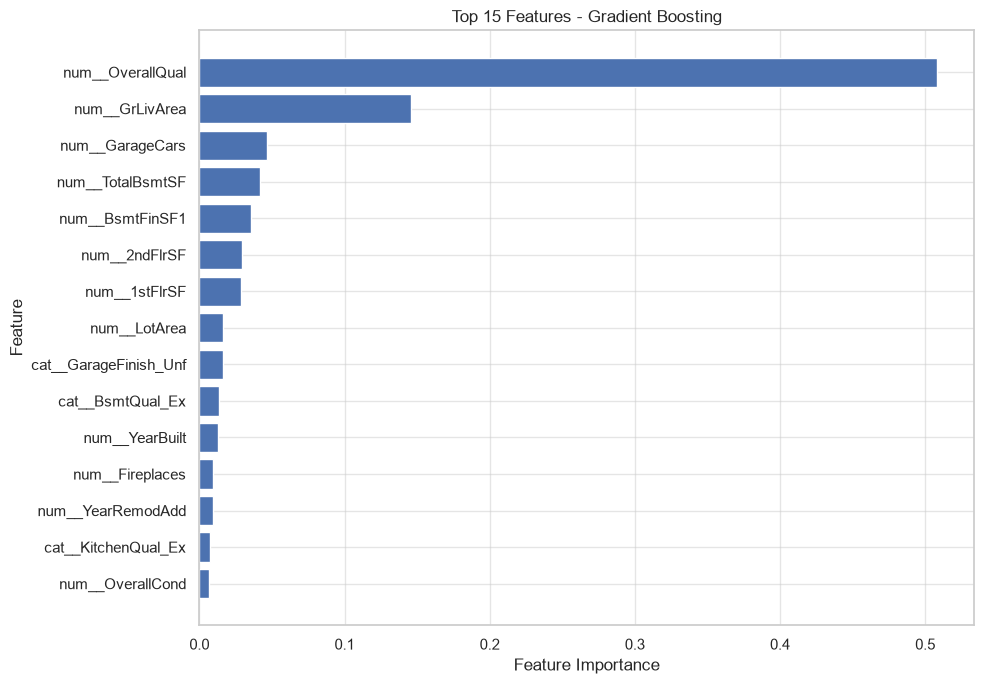

In [77]:
top_features = feature_importance.head(15).sort_values(
    "Importance", ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features - Gradient Boosting")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Feature Importance Analysis

The Gradient Boosting model identifies `OverallQual` as the most influential feature, contributing approximately 51% of the total feature importance. `GrLivArea` is the second most important feature, contributing approximately 15%.

Other influential features include `GarageCars`, `TotalBsmtSF`, `BsmtFinSF1`, `1stFlrSF`, `2ndFlrSF`, and `LotArea`.

**Key observations:**
- Overall material and finish quality has the highest predictive importance.
- Above-ground living area is another major contributor to predicted house prices.
- Garage and basement characteristics provide additional predictive information.
- The model relies heavily on property quality and usable living space.

**Limitations:**

Feature importance indicates how much a feature contributes to the model's predictive decisions. It does not establish causation or indicate whether a feature increases or decreases the predicted price. Correlated features may also share importance.

Further interpretation using permutation importance or SHAP values could provide additional insights.

In [78]:
# Create candidate properties from the unseen validation dataset
buyer_candidates = df.loc[X_valid.index].copy()

# Generate estimated prices using the trained Gradient Boosting model
buyer_candidates["PredictedPrice"] = best_model.predict(X_valid)

# Display candidate properties
candidate_columns = [
    "Id",
    "Neighborhood",
    "OverallQual",
    "GrLivArea",
    "BedroomAbvGr",
    "FullBath",
    "GarageCars",
    "SalePrice",
    "PredictedPrice"
]

display(
    buyer_candidates[candidate_columns]
    .sort_values("PredictedPrice")
    .head(10)
    .round(2)
)

print("Total candidate properties:", len(buyer_candidates))

,Id,Neighborhood,OverallQual,GrLivArea,BedroomAbvGr,FullBath,GarageCars,SalePrice,PredictedPrice
636,637,BrkSide,2,800,1,1,0,60000,"52,839.90"
620,621,Edwards,3,864,2,1,0,67000,"62,995.49"
916,917,IDOTRR,2,480,1,0,1,35311,"71,684.39"
29,30,BrkSide,4,520,1,1,1,68500,"74,492.14"
398,399,IDOTRR,5,1077,2,1,1,67000,"78,349.02"
915,916,MeadowV,4,1092,3,1,1,75000,"81,882.34"
649,650,MeadowV,4,630,1,1,0,84500,"84,626.66"
614,615,MeadowV,4,630,1,1,0,75500,"84,626.66"
736,737,NAmes,3,1040,2,2,2,93500,"88,553.53"
874,875,OldTown,5,1131,3,1,1,66500,"91,689.88"


Total candidate properties: 292


In [79]:
buyer_profiles = {
    "Budget Buyer": {
        "budget": 125000,
        "min_quality": 5,
        "min_living_area": 1000,
        "min_bedrooms": 2,
        "min_bathrooms": 1
    },
    "Mid-Range Buyer": {
        "budget": 200000,
        "min_quality": 6,
        "min_living_area": 1400,
        "min_bedrooms": 3,
        "min_bathrooms": 2
    },
    "Premium Buyer": {
        "budget": 350000,
        "min_quality": 8,
        "min_living_area": 1800,
        "min_bedrooms": 3,
        "min_bathrooms": 2
    }
}

def filter_properties(properties, profile):
    return properties[
        (properties["PredictedPrice"] <= profile["budget"]) &
        (properties["OverallQual"] >= profile["min_quality"]) &
        (properties["GrLivArea"] >= profile["min_living_area"]) &
        (properties["BedroomAbvGr"] >= profile["min_bedrooms"]) &
        (
            properties["FullBath"] + properties["HalfBath"] * 0.5
            >= profile["min_bathrooms"]
        )
    ].copy()

buyer_results = {}

for buyer_name, profile in buyer_profiles.items():
    matches = filter_properties(buyer_candidates, profile)
    buyer_results[buyer_name] = matches

    print(f"\n{buyer_name}")
    print("Matching properties:", len(matches))
    print("Budget:", f"${profile['budget']:,}")


Budget Buyer
Matching properties: 22
Budget: $125,000

Mid-Range Buyer
Matching properties: 39
Budget: $200,000

Premium Buyer
Matching properties: 12
Budget: $350,000


In [80]:
def rank_properties(properties, profile):
    ranked = properties.copy()

    ranked["Budget_Score"] = (
        1 - ranked["PredictedPrice"] / profile["budget"]
    )

    ranked["Quality_Score"] = ranked["OverallQual"] / 10

    # Cap the area score at 1.0 once the property reaches
    # 150% of the buyer's minimum required living area.
    area_cap = profile["min_living_area"] * 1.5

    ranked["Area_Score"] = (
        ranked["GrLivArea"] / area_cap
    ).clip(upper=1.0)

    ranked["Recommendation_Score"] = (
        0.40 * ranked["Budget_Score"] +
        0.40 * ranked["Quality_Score"] +
        0.20 * ranked["Area_Score"]
    )

    return ranked.sort_values(
        "Recommendation_Score",
        ascending=False
    )


ranked_buyer_results = {}

for buyer_name, profile in buyer_profiles.items():
    ranked = rank_properties(
        buyer_results[buyer_name],
        profile
    )

    ranked_buyer_results[buyer_name] = ranked

    print(f"\n{'=' * 60}")
    print(buyer_name)
    print(f"{'=' * 60}")

    display(
        ranked[
            [
                "Id",
                "Neighborhood",
                "PredictedPrice",
                "OverallQual",
                "GrLivArea",
                "Recommendation_Score"
            ]
        ].head(5).round(3)
    )


Budget Buyer


,Id,Neighborhood,PredictedPrice,OverallQual,GrLivArea,Recommendation_Score
398,399,IDOTRR,"78,349.02",5,1077,0.49
874,875,OldTown,"91,689.88",5,1131,0.46
344,345,MeadowV,"92,303.60",5,1112,0.45
1177,1178,OldTown,"111,594.88",6,1224,0.45
1291,1292,BrDale,"103,242.97",5,1302,0.44



Mid-Range Buyer


,Id,Neighborhood,PredictedPrice,OverallQual,GrLivArea,Recommendation_Score
1132,1133,OldTown,"127,232.98",6,2210,0.59
1216,1217,Sawyer,"139,412.12",6,1902,0.54
1088,1089,Edwards,"150,222.96",7,1709,0.54
63,64,OldTown,"150,843.82",7,1710,0.54
576,577,SWISU,"154,614.67",7,1477,0.51



Premium Buyer


,Id,Neighborhood,PredictedPrice,OverallQual,GrLivArea,Recommendation_Score
602,603,SawyerW,"225,233.28",8,1915,0.60
1133,1134,SawyerW,"251,185.32",8,2020,0.58
1447,1448,CollgCr,"265,196.83",8,2090,0.57
1054,1055,CollgCr,"262,599.97",8,1989,0.57
1175,1176,NoRidge,"321,157.76",8,2872,0.55


In [81]:
recommendation_tables = []

for buyer_name, profile in buyer_profiles.items():
    top_properties = ranked_buyer_results[buyer_name].head(5).copy()

    top_properties["Buyer_Profile"] = buyer_name
    top_properties["Buyer_Budget"] = profile["budget"]

    top_properties["Budget_Remaining"] = (
        profile["budget"] - top_properties["PredictedPrice"]
    )

    top_properties["Bathrooms"] = (
        top_properties["FullBath"] +
        top_properties["HalfBath"] * 0.5
    )

    recommendation_tables.append(
        top_properties[
            [
                "Buyer_Profile",
                "Id",
                "Neighborhood",
                "PredictedPrice",
                "Budget_Remaining",
                "OverallQual",
                "GrLivArea",
                "BedroomAbvGr",
                "Bathrooms",
                "Recommendation_Score"
            ]
        ]
    )

final_recommendations = pd.concat(
    recommendation_tables,
    ignore_index=True
)

display(final_recommendations.round(2))

,Buyer_Profile,Id,Neighborhood,PredictedPrice,Budget_Remaining,OverallQual,GrLivArea,BedroomAbvGr,Bathrooms,Recommendation_Score
0,Budget Buyer,399,IDOTRR,"78,349.02","46,650.98",5,1077,2,1.00,0.49
1,Budget Buyer,875,OldTown,"91,689.88","33,310.12",5,1131,3,1.50,0.46
2,Budget Buyer,345,MeadowV,"92,303.60","32,696.40",5,1112,3,1.50,0.45
3,Budget Buyer,1178,OldTown,"111,594.87","13,405.13",6,1224,3,1.00,0.45
4,Budget Buyer,1292,BrDale,"103,242.97","21,757.03",5,1302,3,2.50,0.44
5,Mid-Range Buyer,1133,OldTown,"127,232.98","72,767.02",6,2210,5,2.00,0.59
6,Mid-Range Buyer,1217,Sawyer,"139,412.12","60,587.88",6,1902,4,2.00,0.54
7,Mid-Range Buyer,1089,Edwards,"150,222.96","49,777.04",7,1709,3,2.00,0.54
8,Mid-Range Buyer,64,OldTown,"150,843.82","49,156.18",7,1710,3,2.00,0.54
9,Mid-Range Buyer,577,SWISU,"154,614.67","45,385.33",7,1477,3,2.00,0.51


## Buyer Recommendation System

### Objective
Develop a rule-based recommendation system that identifies and ranks properties according to buyer budgets, property quality, living area, bedroom requirements, and bathroom requirements.

### Methodology

1. Generate predicted prices using the trained Gradient Boosting model.
2. Filter properties according to each buyer's budget and minimum property requirements.
3. Calculate affordability, quality, and living-area scores.
4. Combine these scores using weighted scoring:
   - Affordability: 40%
   - Overall Quality: 40%
   - Living Area: 20%
5. Rank matching properties by their recommendation scores.
6. Return the top five properties for each buyer profile.

### Recommendation Results

| Buyer Profile | Matching Properties | Top Recommendation |
|---|---:|---|
| Budget Buyer | 22 | Id 399, IDOTRR |
| Mid-Range Buyer | 39 | Id 1133, OldTown |
| Premium Buyer | 12 | Id 603, SawyerW |

### Limitations

- Buyer profiles use predefined requirements and may not represent every buyer's preferences.
- Recommendation weights are heuristic and have not been validated against actual buyer preferences.
- Predicted prices are estimates, not guaranteed transaction prices.
- The recommendations use historical validation-set properties rather than live property listings.
- Neighborhood desirability, transportation, schools, property taxes, and other external factors are not included.

### Conclusion

The recommendation system demonstrates how a house-price prediction model can support property selection by combining estimated prices with buyer-specific requirements. It provides a foundation for a more advanced personalized property recommendation application.

## Model Comparison Report

### 1. Objective

The objective is to evaluate multiple regression algorithms and select the most suitable model for predicting residential house prices.

The following models were evaluated:

- Linear Regression
- Random Forest Regressor
- Gradient Boosting Regressor
- Gradient Boosting with a log-transformed target
- Tuned Gradient Boosting Regressor

### 2. Validation Performance Comparison

All models were evaluated using the same 20% validation dataset.

| Model | MAE (`$`) | RMSE (`$`) | R^2 |
|---|---:|---:|---:|
| Linear Regression | 20,466.13 | 31,294.99 | 0.8723 |
| Random Forest | 17,350.76 | 28,376.65 | 0.8950 |
| Gradient Boosting | 16,946.24 | 27,667.91 | 0.9002 |
| Gradient Boosting (Log Target) | 16,702.71 | 30,406.13 | 0.8795 |

### 3. Cross-Validation Performance

Five-fold cross-validation was conducted using the training dataset.

| Model | Mean CV MAE (`$`) | Mean CV RMSE (`$`) | Mean CV R^2 |
|---|---:|---:|---:|
| Random Forest | 18,143.70 | 30,264.36 | 0.84 |
| Gradient Boosting | 16,027.75 | 28,161.69 | 0.86 |
| Tuned Gradient Boosting | 17,841.26 | 30,455.70 | 0.84 |

The original Gradient Boosting configuration performed better than the tested tuned configuration across all three cross-validation metrics.

### 4. Model Evaluation

- Linear Regression provides a baseline but has higher prediction errors.
- Random Forest improves on the baseline and provides competitive results.
- Gradient Boosting achieves the lowest validation RMSE and highest validation R^2 among the models evaluated on the original target scale.
- Log-target Gradient Boosting achieves the lowest validation MAE, but its RMSE and R^2 are worse than the original-target Gradient Boosting model.
- The tested tuned Gradient Boosting configuration does not improve cross-validation performance.

### 5. Final Model Selection

**Selected model: Gradient Boosting Regressor with the original SalePrice target.**

Reasons for selection:

1. Lowest validation RMSE among the original-target models.
2. Highest validation R^2 of approximately 0.90.
3. Better five-fold cross-validation performance than Random Forest.
4. Better cross-validation performance than the tested tuned configuration.
5. Produces predictions directly in the original currency scale.

The model explains approximately 90% of the variation in the validation target according to R^2.

### 6. Production Considerations

Before production deployment, additional work would be required:

- Evaluate performance on an independent external dataset.
- Monitor prediction errors across different price ranges.
- Investigate influential observations and unusual properties.
- Track model performance over time.
- Validate preprocessing and prediction consistency.
- Consider model retraining as housing-market patterns change.

### Conclusion

The Gradient Boosting Regressor is the strongest candidate among the tested models based on the current validation and cross-validation experiments. It provides a reasonable balance of predictive accuracy and generalization performance for this capstone project. Further external validation would be required before production deployment.

## Report on Challenges Faced

### 1. Missing Values

**Challenge:** The dataset contained missing values across several numerical and categorical features. Some columns had substantial missingness, including PoolQC (99.52%), MiscFeature (96.30%), Alley (93.77%), and Fence (80.75%).

**Investigation and solution:**
- Investigated whether missing values represented unavailable property features rather than missing observations.
- Found that missing PoolQC values corresponded to properties with zero pool area.
- Found that missing GarageType values corresponded to properties with zero garage capacity and area.
- Found similar structural patterns for basements and fireplaces.
- Used median imputation for numerical features and most-frequent imputation for categorical features in the baseline preprocessing pipeline.

**Learning:** Missing values must be interpreted using domain context before selecting an imputation strategy.

### 2. Skewed Target Distribution

**Challenge:** The SalePrice target had a positive skewness of approximately 1.883.

**Investigation and solution:**
- Examined the original target distribution.
- Applied a logarithmic transformation using `log1p` as an experiment.
- The transformed target had skewness of approximately 0.12.
- Compared Gradient Boosting models trained on the original and transformed targets.
- Retained the original target model because it achieved better RMSE and R^2 on the validation dataset.

**Learning:** Target transformations can improve distributional characteristics but must be evaluated using model performance.

### 3. Outliers and Influential Observations

**Challenge:** Several properties had unusually large living areas or high sale prices.

**Investigation and solution:**
- Used the IQR method to identify potential outliers.
- Investigated unusually large properties with IDs 524 and 1299.
- Verified their living-area and basement-area calculations.
- Found that both properties had unusually low prices per square foot compared with other Partial sales.
- Conducted a sensitivity experiment by training another model without these two observations.
- Observed improved validation and cross-validation metrics after excluding them.

**Decision:** Retained the original dataset and documented the observations as influential rather than automatically deleting them.

**Learning:** Statistical outliers are not necessarily data errors. Their influence should be investigated before removal.

### 4. Feature Relationships and Multicollinearity

**Challenge:** Several property characteristics were strongly associated with one another and with SalePrice.

**Investigation and solution:**
- Examined numerical correlations.
- Identified OverallQual and GrLivArea as strongly associated with SalePrice.
- Examined neighborhood, property quality, and property age relationships.
- Used a Gradient Boosting feature-importance analysis to identify influential predictors.

**Learning:** Feature relationships help explain model behaviour, but correlation does not establish causation.

### 5. Model Selection and Generalization

**Challenge:** Different algorithms produced different prediction errors.

**Investigation and solution:**
- Evaluated Linear Regression, Random Forest, and Gradient Boosting.
- Compared models using MAE, RMSE, and R^2.
- Performed five-fold cross-validation.
- Tested a log-transformed target and an alternative Gradient Boosting configuration.
- Selected the original-target Gradient Boosting model based on its overall validation and cross-validation performance.

**Learning:** Model selection should consider multiple metrics and cross-validation rather than relying on a single evaluation score.

### 6. Buyer Recommendation Design

**Challenge:** Predicting house prices alone does not directly help buyers identify suitable properties.

**Investigation and solution:**
- Defined Budget, Mid-Range, and Premium buyer profiles.
- Applied budget, quality, living-area, bedroom, and bathroom filters.
- Used predicted prices rather than actual sale prices for budget eligibility.
- Developed a weighted ranking score using affordability, quality, and living area.
- Limited the area score to prevent exceptionally large properties from dominating recommendations.

**Learning:** A recommendation system requires both predictive modelling and user-specific decision criteria.

### 7. Summary of Key Lessons

The project provided practical experience in:

- Data quality assessment and missing-value treatment.
- Exploratory data analysis and statistical investigation.
- Feature relationships and feature importance.
- Regression model development and evaluation.
- Cross-validation and sensitivity analysis.
- Buyer-oriented recommendation logic.
- Interpreting model limitations and avoiding unsupported conclusions.

In [82]:
# Validate the final recommendation results
validation_results = []

for buyer_name, profile in buyer_profiles.items():
    recommendations = ranked_buyer_results[buyer_name].head(5)

    checks = {
        "Within budget": (
            recommendations["PredictedPrice"] <= profile["budget"]
        ).all(),

        "Minimum quality": (
            recommendations["OverallQual"] >= profile["min_quality"]
        ).all(),

        "Minimum living area": (
            recommendations["GrLivArea"] >= profile["min_living_area"]
        ).all(),

        "Minimum bedrooms": (
            recommendations["BedroomAbvGr"] >= profile["min_bedrooms"]
        ).all(),

        "Minimum bathrooms": (
            recommendations["FullBath"] +
            recommendations["HalfBath"] * 0.5
            >= profile["min_bathrooms"]
        ).all(),

        "Five recommendations": len(recommendations) == 5
    }

    for check_name, passed in checks.items():
        validation_results.append({
            "Buyer": buyer_name,
            "Check": check_name,
            "Status": "PASS" if passed else "FAIL"
        })

audit_results = pd.DataFrame(validation_results)

display(audit_results)
print("\nAll checks passed:", (audit_results["Status"] == "PASS").all())

,Buyer,Check,Status
0,Budget Buyer,Within budget,PASS
1,Budget Buyer,Minimum quality,PASS
2,Budget Buyer,Minimum living area,PASS
3,Budget Buyer,Minimum bedrooms,PASS
4,Budget Buyer,Minimum bathrooms,PASS
5,Budget Buyer,Five recommendations,PASS
6,Mid-Range Buyer,Within budget,PASS
7,Mid-Range Buyer,Minimum quality,PASS
8,Mid-Range Buyer,Minimum living area,PASS
9,Mid-Range Buyer,Minimum bedrooms,PASS



All checks passed: True
